# 🛒 Olist E-Commerce — Exploratory Data Analysis
**Notebook 2 of 2** | See `Olist_Sales_Cleaned.ipynb` for the data preparation pipeline

---

## About this notebook
End-to-end exploratory data analysis on the cleaned Olist Brazilian E-Commerce dataset.  
Every section follows the same structure: **business question → code → finding → recommendation**.

**Dataset:** [Olist Brazilian E-Commerce](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)  
**Analysis period:** January 2017 – July 2018 (stable operating period)  
**Scope:** 96,469 delivered orders · 81,005 unique customers  
**Tools:** Python · Pandas · Matplotlib · Seaborn · Plotly

---

## Table of Contents
1. [Setup — Imports & Data Load](#setup)
2. [Analysis Period Definition](#period)
3. [Section 1 — Revenue Analysis](#revenue)
4. [Section 2 — Product Analysis](#products)
5. [Section 3 — Customer Behavior](#customers)
6. [Section 4 — Geographic Analysis](#geography)
7. [Section 5 — RFM Segmentation](#rfm)
8. [Section 6 — Review Analysis](#reviews)
9. [Key Findings Summary](#summary)


---

## 1. Setup — Imports & Data Load <a id='setup'></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.dpi'] = 130
plt.rcParams['figure.figsize'] = (12,5)

### Load clean data

Three files produced by the cleaning pipeline are loaded here.

| Dataframe | Rows | Grain | Primary use |
|-----------|------|-------|-------------|
| `master_orders` | 96,469 | 1 row = 1 order | Revenue, customers, RFM, reviews |
| `master_products` | 112,650 | 1 row = 1 order item | Product category analysis |
| `reviews_text` | 36,848 | Reviews with text only | Sentiment analysis (AI feature) |


In [ ]:
master_orders = pd.read_csv('/content/master_orders.csv',
                            parse_dates=['order_purchase_timestamp',
                                         'order_delivered_customer_date',
                                         'order_estimated_delivery_date',
                                         'order_approved_at',
                                         'order_delivered_carrier_date'])
master_products = pd.read_csv('/content/msater_products.csv')
reviews_text = pd.read_csv('/content/reviews_text_clean.csv')

print(f"master_orders:   {master_orders.shape}")
print(f"master_products: {master_products.shape}")
print(f"reviews_text:    {reviews_text.shape}")

master_orders:   (96469, 24)
master_products: (112650, 13)
reviews_text:    (36848, 7)


---

## 2. Analysis Period Definition <a id='period'></a>

Two boundary issues exist at the edges of the dataset requiring careful filtering
before any time-series analysis.

**Issue 1 — Soft-launch period (Sep–Dec 2016):**  
Order volumes ranged from 1 to 265/month vs 700+ from Jan 2017 onward.  
These near-zero months produce meaningless MoM growth rates — one month  
showed >600,000% growth purely from a near-zero prior base.

**Issue 2 — Incomplete final month (Aug 2018):**  
Data collection ends Aug 29, 2018 — not a full month.  
Including it creates a false "revenue decline" signal in the final period.

**Decision:** Analysis filtered to **Jan 2017 – Jul 2018** (19 complete months).

| Dataframe | Period | Used for |
|-----------|--------|----------|
| `master_orders_stable` | Jan 2017 – Jul 2018 | Revenue, customer, RFM analysis |
| `master_orders_full` | Sep 2016 – Aug 2018 | Geography, reviews (not time-sensitive) |


In [ ]:
# Full dataset — for geography and reviews (not time-sensitive)
master_orders_full = master_orders.copy()

# Stable period — for time-series, customer, and RFM analysis
master_orders_stable = master_orders[
    (master_orders['order_purchase_timestamp'] >= '2017-01') &
    (master_orders['order_purchase_timestamp'] <= '2018-07')
].copy()

print(f"Full dataset:    {len(master_orders_full):,} orders")
print(f"Stable period:   {len(master_orders_stable):,} orders")
print(f"Excluded:        {len(master_orders_full) - len(master_orders_stable):,} orders "
      f"(soft-launch + incomplete final month)")

Full dataset:    96,469 orders
Stable period:   83,695 orders
Excluded:        12,774 orders (soft-launch + incomplete final month)


---

## Section 1 — Revenue Analysis <a id='revenue'></a>

**Business questions answered in this section:**
- What is the monthly revenue trend over 18 months?
- Which months grew or declined and by how much?
- When do customers place orders — what day and hour sees the most activity?


### 1.1 — What is the monthly revenue trend?

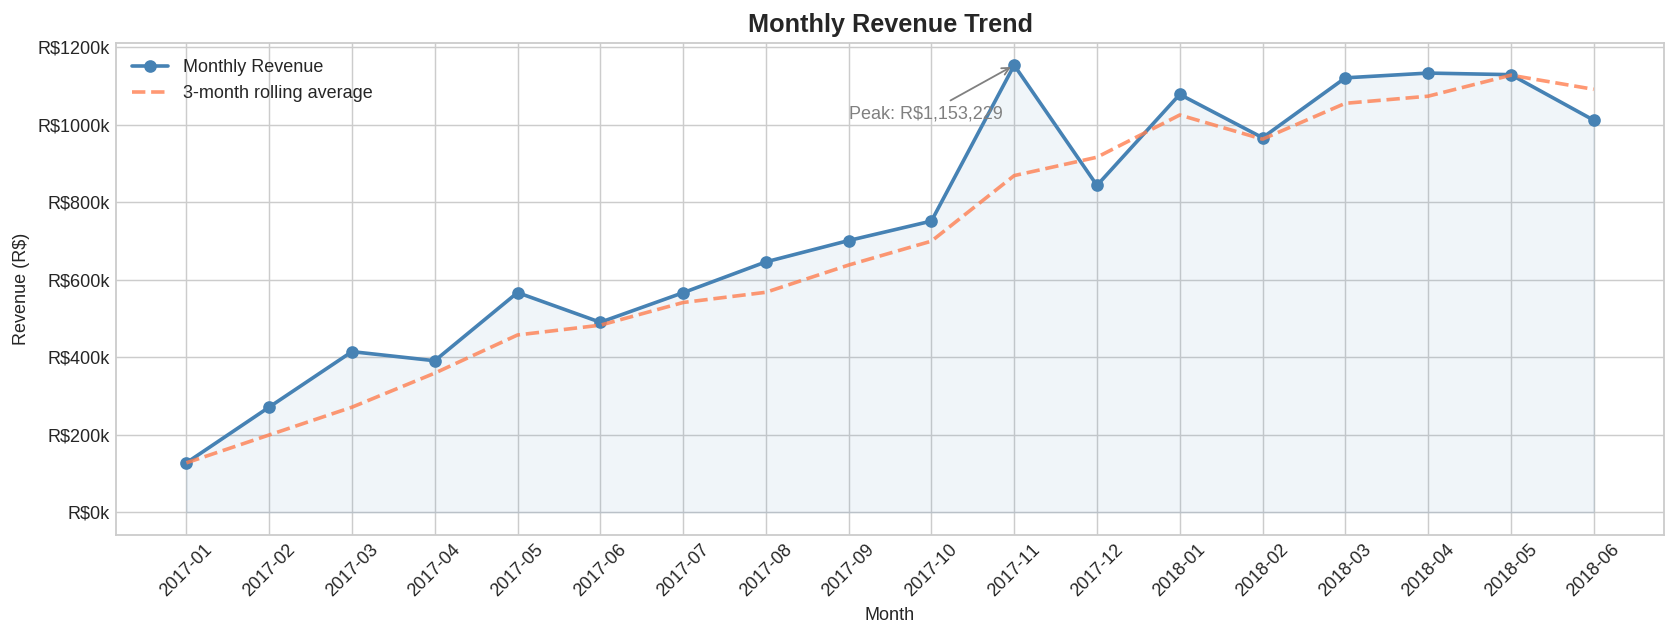

In [ ]:
# Monthly revenue with 3-month rolling average
monthly_full = (master_orders_stable
           .groupby('purchase_month')
           .agg(revenue = ('total_revenue','sum'),
                orders = ('order_id','count'),
                aov = ('total_revenue','mean'))
           .reset_index())

monthly_full['rolling_avg'] = monthly_full['revenue'].rolling(3, min_periods=1).mean()
monthly_full['mom_growth'] = monthly_full['revenue'].pct_change() * 100

fig, ax = plt.subplots(figsize=(13,5))
ax.plot(monthly_full['purchase_month'], monthly_full['revenue'],
        marker='o', linewidth=2, color='steelblue', label='Monthly Revenue')
ax.plot(monthly_full['purchase_month'], monthly_full['rolling_avg'],
        linewidth=2, linestyle='--', color='coral', alpha=0.8, label='3-month rolling average')
ax.fill_between(range(len(monthly_full)), monthly_full['revenue'], alpha=0.08, color='steelblue')

# Annotate peak
peak = monthly_full.loc[monthly_full['revenue'].idxmax()]
peak_pos = monthly_full.index.get_loc(peak.name)
ax.annotate(f"Peak: R${peak['revenue']:,.0f}",
            xy=(peak_pos, peak['revenue']),
            xytext=(peak_pos-2, peak['revenue']*0.88),
            arrowprops=dict(arrowstyle='->', color='gray'),
            fontsize=10, color='gray')

ax.set_title('Monthly Revenue Trend', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Revenue (R$)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'R${x/1000:.0f}k'))
ax.tick_params(axis='x', rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

### 1.2 — What is the month-over-month growth rate?

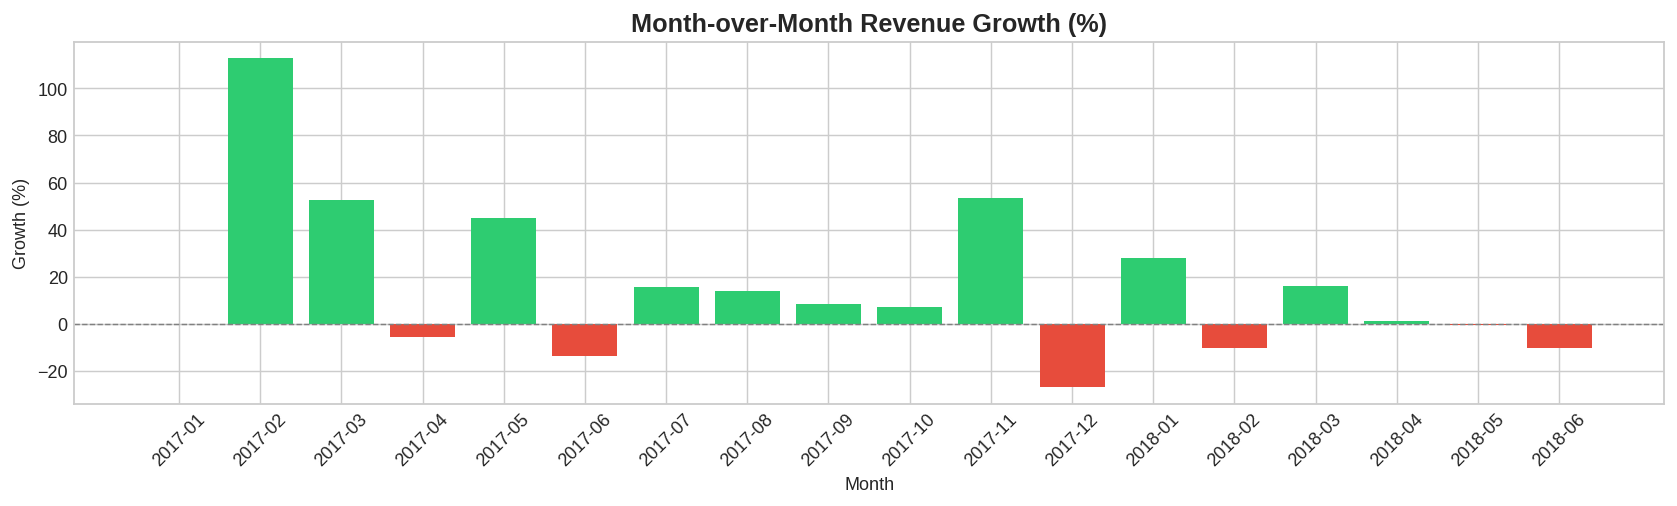

In [ ]:
# MoM Growth — green = positive, red = negative
fig, ax = plt.subplots(figsize=(13,4))
colors = ['#2ecc71' if x >= 0 else '#e74c3c' for x in monthly_full['mom_growth'].fillna(0)]
ax.bar(monthly_full['purchase_month'], monthly_full['mom_growth'].fillna(0), color=colors)
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_title('Month-over-Month Revenue Growth (%)', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Growth (%)')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### Supporting statistics — peak, trough, and growth metrics

In [ ]:
# Peak month
peak_row = monthly_full.loc[monthly_full['revenue'].idxmax()]
print(f"Peak month:           {peak_row['purchase_month']}")
print(f"Peak revenue:         R${peak_row['revenue']:,.0f}")
print(f"MoM growth that month: {peak_row['mom_growth']:.1f}%")

# Biggest single-month drop
trough = monthly_full.loc[monthly_full['mom_growth'].idxmin()]
print(f"\nBiggest MoM decline: {trough['purchase_month']}")
print(f"Decline:             {trough['mom_growth']:.1f}%")

print(f"\nTotal revenue (stable period): R${monthly_full['revenue'].sum():,.0f}")
print(f"Average monthly revenue:       R${monthly_full['revenue'].mean():,.0f}")

Peak month:           2017-11
Peak revenue:         R$1,153,229
MoM growth that month: 53.5%

Biggest MoM decline: 2017-12
Decline:             -26.9%

Total revenue (stable period): R$13,358,769
Average monthly revenue:       R$742,154


---

### 📌 Finding — Monthly Revenue Trend

Revenue peaked in **November 2017 at R\$1.15M** — a 53.5% spike vs the prior month,  
almost certainly driven by Black Friday bringing first-time buyers onto the platform.  
December 2017 saw a ~27% post-holiday correction, a typical seasonal pattern  
for marketplace businesses.

The 3-month rolling average confirms an underlying upward trend throughout  
the stable period — the platform was growing structurally, not just seasonally.

**Business recommendation:** November is Olist's single most important revenue month.  
Inventory, logistics, and marketing resources should be concentrated here.  
The December correction is predictable and should not trigger overreaction in planning cycles.


---

### 1.3 — When do customers place orders?

**Question:** Is there a single peak hour or a broad active window?  
Understanding order timing informs when to run campaigns, push notifications, and flash sales.


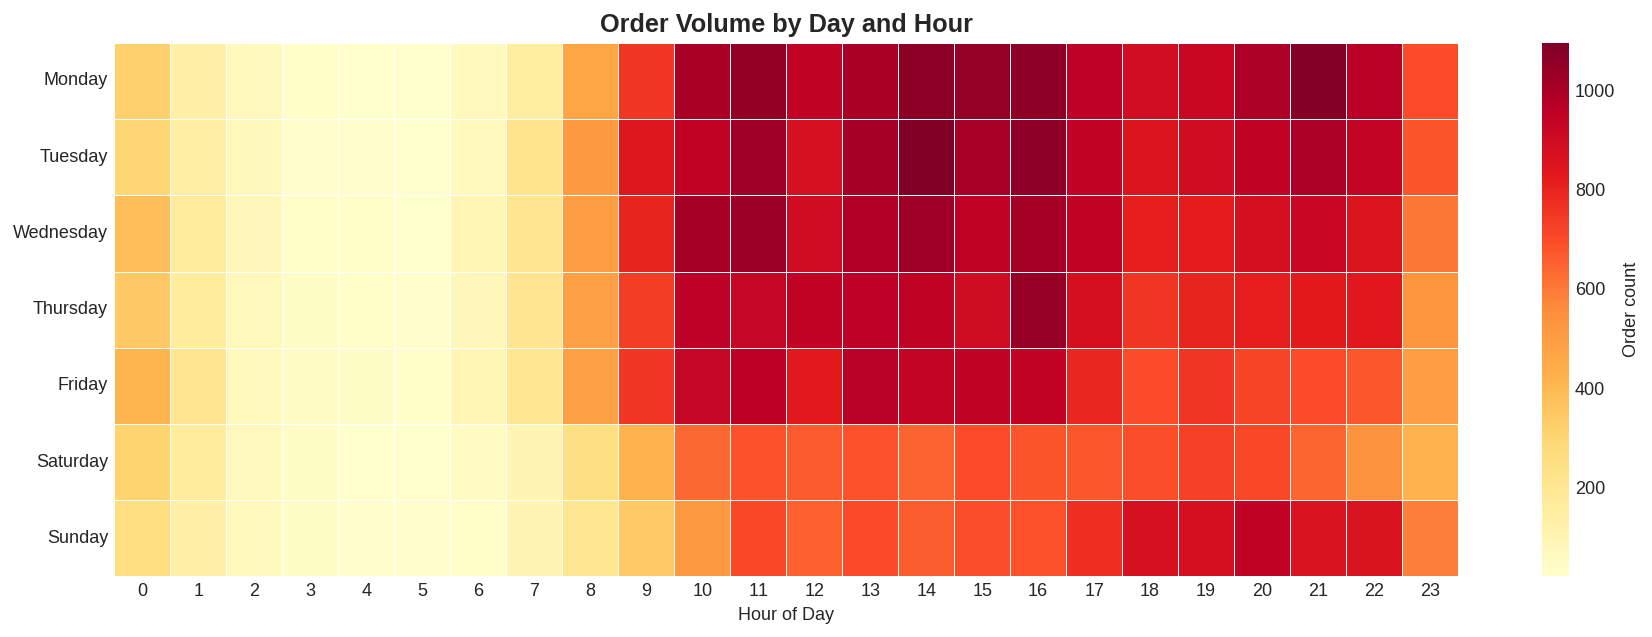

In [ ]:
# Day × Hour order volume heatmap
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
heatmap_data = (master_orders_full
                .groupby(['purchase_day','purchase_hour'])['order_id']
                .count()
                .unstack(fill_value=0)
                .reindex(day_order))

fig, ax = plt.subplots(figsize=(14,5))
sns.heatmap(heatmap_data, cmap='YlOrRd', ax=ax, fmt='d',
            linewidths=0.3, cbar_kws={'label':'Order count'})
ax.set_title("Order Volume by Day and Hour", fontweight='bold', fontsize=14)
ax.set_xlabel('Hour of Day')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

### Supporting statistics — hourly breakdown, peak window, and overnight analysis

In [ ]:
# Hourly order totals
hourly_totals = heatmap_data.sum().reset_index()
hourly_totals.columns = ['hour','total_orders']
print("Hourly order totals:")
print(hourly_totals.to_string(index=False))

Hourly order totals:
 hour  total_orders
    0          2321
    1          1133
    2           496
    3           259
    4           203
    5           182
    6           477
    7          1199
    8          2906
    9          4647
   10          5978
   11          6385
   12          5802
   13          6309
   14          6383
   15          6249
   16          6475
   17          5961
   18          5585
   19          5801
   20          6007
   21          6039
   22          5658
   23          4014


In [ ]:
# Peak window — hours above 75th percentile
threshold = hourly_totals['total_orders'].quantile(0.75)
peak_hours = hourly_totals[hourly_totals['total_orders'] >= threshold]
busiest_hour = hourly_totals.loc[hourly_totals['total_orders'].idxmax()]

print(f"75th percentile threshold: {threshold:,.0f} orders")
print(f"Peak window: {int(peak_hours['hour'].min())}:00 — {int(peak_hours['hour'].max())}:00")
print(f"Single busiest hour: {int(busiest_hour['hour'])}:00 with {busiest_hour['total_orders']:,} orders")

75th percentile threshold: 6,015 orders
Peak window: 11:00 — 21:00
Single busiest hour: 16:00 with 6,475 orders


In [ ]:
# Overnight vs daytime volume
overnight = hourly_totals[hourly_totals['hour'].between(0,7)]['total_orders'].sum()
daytime   = hourly_totals[hourly_totals['hour'].between(8,23)]['total_orders'].sum()
print(f"Overnight (0–7am): {overnight:,} orders ({overnight/(overnight+daytime)*100:.1f}% of total)")
print(f"Active (8am–11pm): {daytime:,} orders ({daytime/(daytime+overnight)*100:.1f}% of total)")

Overnight (0–7am): 6,270 orders (6.5% of total)
Active (8am–11pm): 90,199 orders (93.5% of total)


In [ ]:
# Midnight spike investigation — consistent across all days?
midnight_by_day = master_orders_stable[
    master_orders_stable['purchase_hour'] == 0
].groupby('purchase_day')['order_id'].count()
print("Midnight orders by day of week:")
print(midnight_by_day)
print("\nNote: even distribution across all days → UTC timezone offset, not behaviour")

Midnight orders by day of week:
purchase_day
Friday       366
Monday       271
Saturday     279
Sunday       224
Thursday     298
Tuesday      266
Wednesday    335
Name: order_id, dtype: int64

Note: even distribution across all days → UTC timezone offset, not behaviour


In [ ]:
# Peak day/hour combination and weekday vs weekend comparison
peak_cell  = heatmap_data.stack().idxmax()
peak_count = heatmap_data.stack().max()
print(f"Peak slot: {peak_cell[0]} at {peak_cell[1]}:00 — {peak_count:,} orders")

weekdays = ['Monday','Tuesday','Wednesday','Thursday','Friday']
weekend  = ['Saturday','Sunday']
wd_total = heatmap_data.loc[weekdays].sum().sum()
we_total = heatmap_data.loc[weekend].sum().sum()
print(f"\nWeekday orders: {wd_total:,}")
print(f"Weekend orders:  {we_total:,}")
print(f"Weekend is {we_total/wd_total*100:.1f}% of weekday volume")

Peak slot: Tuesday at 14:00 — 1,095 orders

Weekday orders: 74,282
Weekend orders:  22,187
Weekend is 29.9% of weekday volume


---

### 📌 Finding — Order Volume by Day and Hour

Olist shows a broad, sustained **10-hour active window (11:00–21:00)** rather than  
a single lunch-hour spike typical of many e-commerce platforms. The single busiest  
slot is **16:00 with 6,475 orders**, but 10 other hours are within 10% of that figure —  
campaign scheduling flexibility across this window is very high.

The overnight period (midnight–7am) accounts for just **6.5% of daily volume**,  
bottoming at 4–5am. Midnight (hour 0) records a disproportionate 2,321 orders  
— consistent across all 7 days of the week, pointing to a **UTC timezone offset  
artifact** (Brazil is UTC-3) rather than genuine midnight purchasing behaviour.

**Business recommendation:** The real opportunity is the **8–9am window** — capturing  
customers at the start of their day just as order volume begins its sharp daily ramp-up,  
before attention competition peaks later in the afternoon.


---

## Section 2 — Product Analysis <a id='products'></a>

**Business questions answered in this section:**
- Which categories drive the most revenue?
- Do high-revenue categories also have high order volumes — or are some premium/niche?
- Which categories are growing vs declining over time?

> **Note:** `master_products_stable` is used here so that trend charts are not  
> distorted by near-zero 2016 soft-launch values.


In [ ]:
# Filter products to stable period — same reasoning as master_orders_stable
master_products_stable = master_products[
    (master_products['purchase_month'] >= '2017-01') &
    (master_products['purchase_month'] <= '2018-07')
].copy()

print(f"master_products_stable: {master_products_stable.shape}")

master_products_stable: (102729, 13)


### 2.1 — Build category statistics table

In [ ]:
# Aggregate to category level
cat_stats = (master_products_stable
             .groupby('category_english')
             .agg(revenue      = ('price', 'sum'),
                  orders       = ('order_id', 'nunique'),
                  items_sold   = ('order_item_id', 'count'),
                  avg_price    = ('price', 'mean'))
             .reset_index()
             .sort_values('revenue', ascending=False))

# Derived metrics
cat_stats['items_per_order']       = cat_stats['items_sold'] / cat_stats['orders']
cat_stats['order_penetration_pct'] = (cat_stats['orders'] /
                                      master_products_stable['order_id'].nunique() * 100).round(2)
cat_stats['avg_order_revenue']     = cat_stats['revenue'] / cat_stats['orders']

print(cat_stats.head(10)[['category_english','revenue','orders','items_per_order',
                           'order_penetration_pct','avg_order_revenue','avg_price']]
      .sort_values('avg_order_revenue', ascending=False).to_string(index=False))

     category_english    revenue  orders  items_per_order  order_penetration_pct  avg_order_revenue  avg_price
        watches_gifts 1093420.85    5102         1.066641                   5.68         214.312201 200.922611
           cool_stuff  593363.11    3436         1.045402                   3.82         172.690079 165.190175
                 auto  532688.51    3456         1.088252                   3.85         154.134407 141.634807
        health_beauty 1110166.49    7845         1.094583                   8.73         141.512618 129.284557
computers_accessories  847891.96    6137         1.175819                   6.83         138.160658 117.501657
         garden_tools  452820.70    3323         1.241950                   3.70         136.268643 109.721517
       sports_leisure  901801.22    7080         1.121751                   7.88         127.373054 113.548378
      furniture_decor  664889.62    5916         1.295470                   6.58         112.388374  86.754909
 

> **📝 Note on order counting:**  
> A single order can contain items from multiple categories. The `orders` metric  
> counts how many distinct orders contained at least one item from each category —  
> meaning one order can be counted across multiple categories simultaneously.  
> Total order counts across categories will therefore exceed the actual order count  
> in `master_orders`. This is intentional: it answers *"how many customers bought  
> from this category?"* not *"how many orders belonged exclusively to this category?"*


### 2.2 — Top 15 categories by revenue

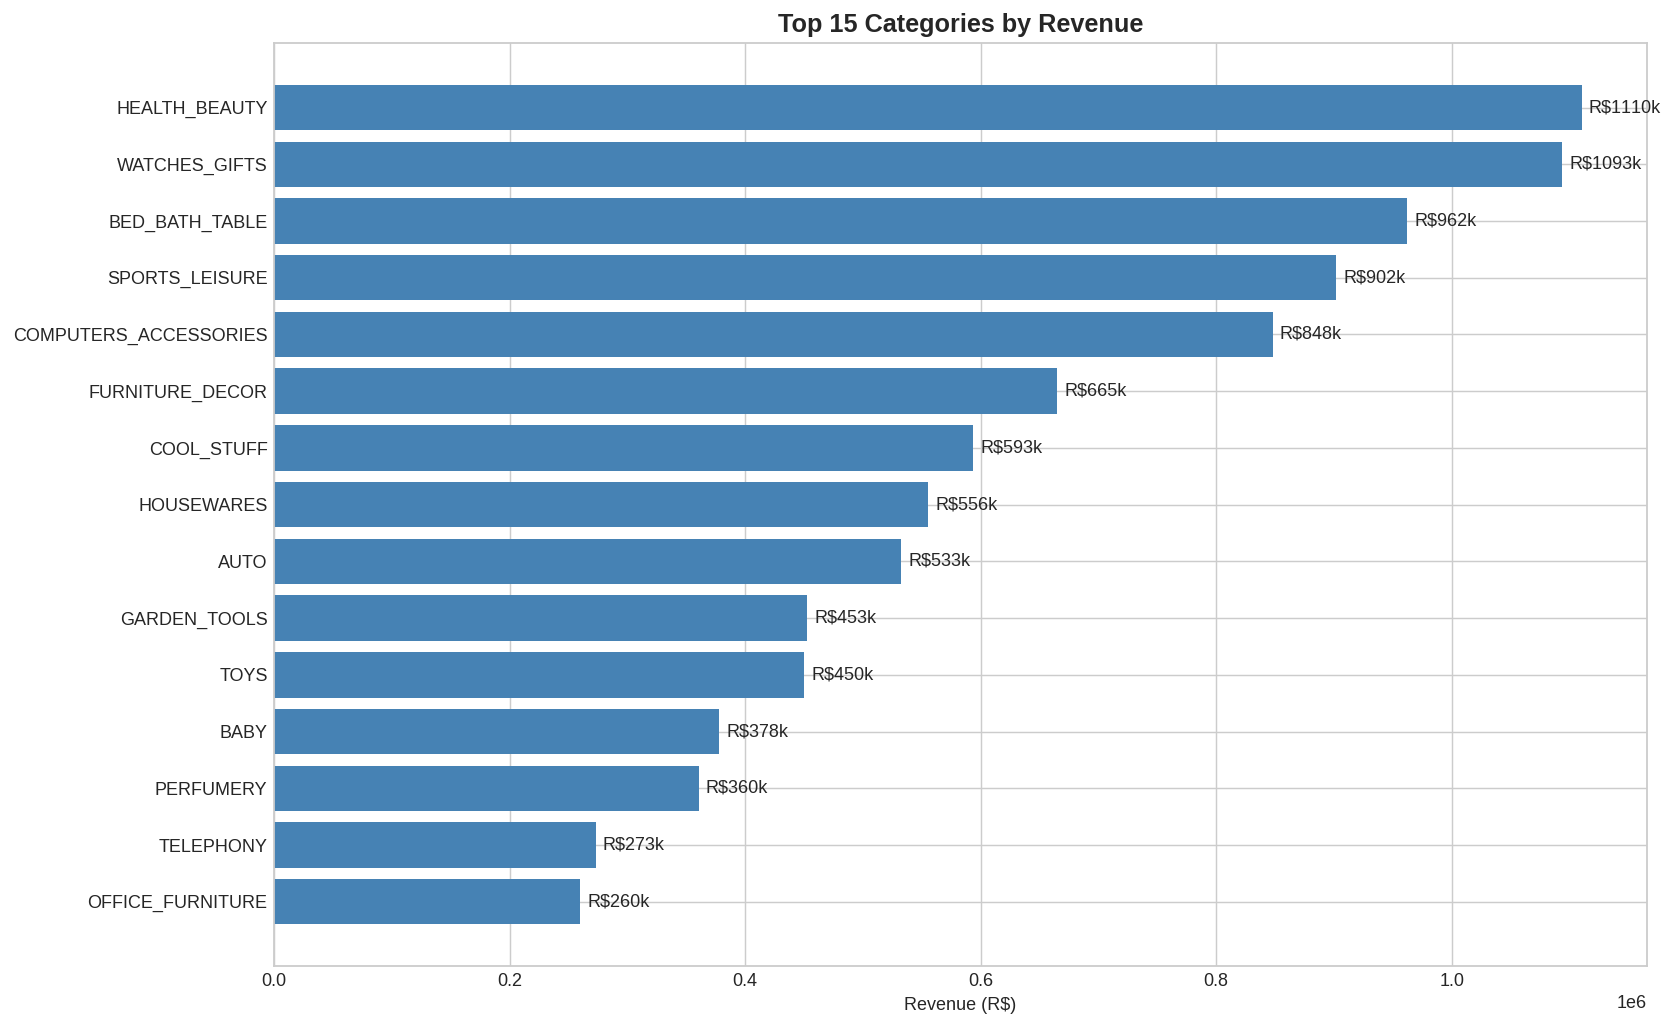

In [ ]:
top_15 = cat_stats.head(15).copy()

fig, ax = plt.subplots(figsize=(13,8))
bars = ax.barh(top_15['category_english'].str.upper(), top_15['revenue'], color='steelblue')
ax.bar_label(bars, labels=[f"R${v/1000:.0f}k" for v in top_15['revenue']], padding=4, fontsize=10)
ax.set_title("Top 15 Categories by Revenue", fontweight='bold', fontsize=14)
ax.set_xlabel('Revenue (R$)')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 2.3 — Revenue vs order count scatter

**What this reveals:** Categories plotted by order volume (x-axis) and total revenue (y-axis).  
Bubble size encodes average order value — makes premium vs volume profiles immediately visible.


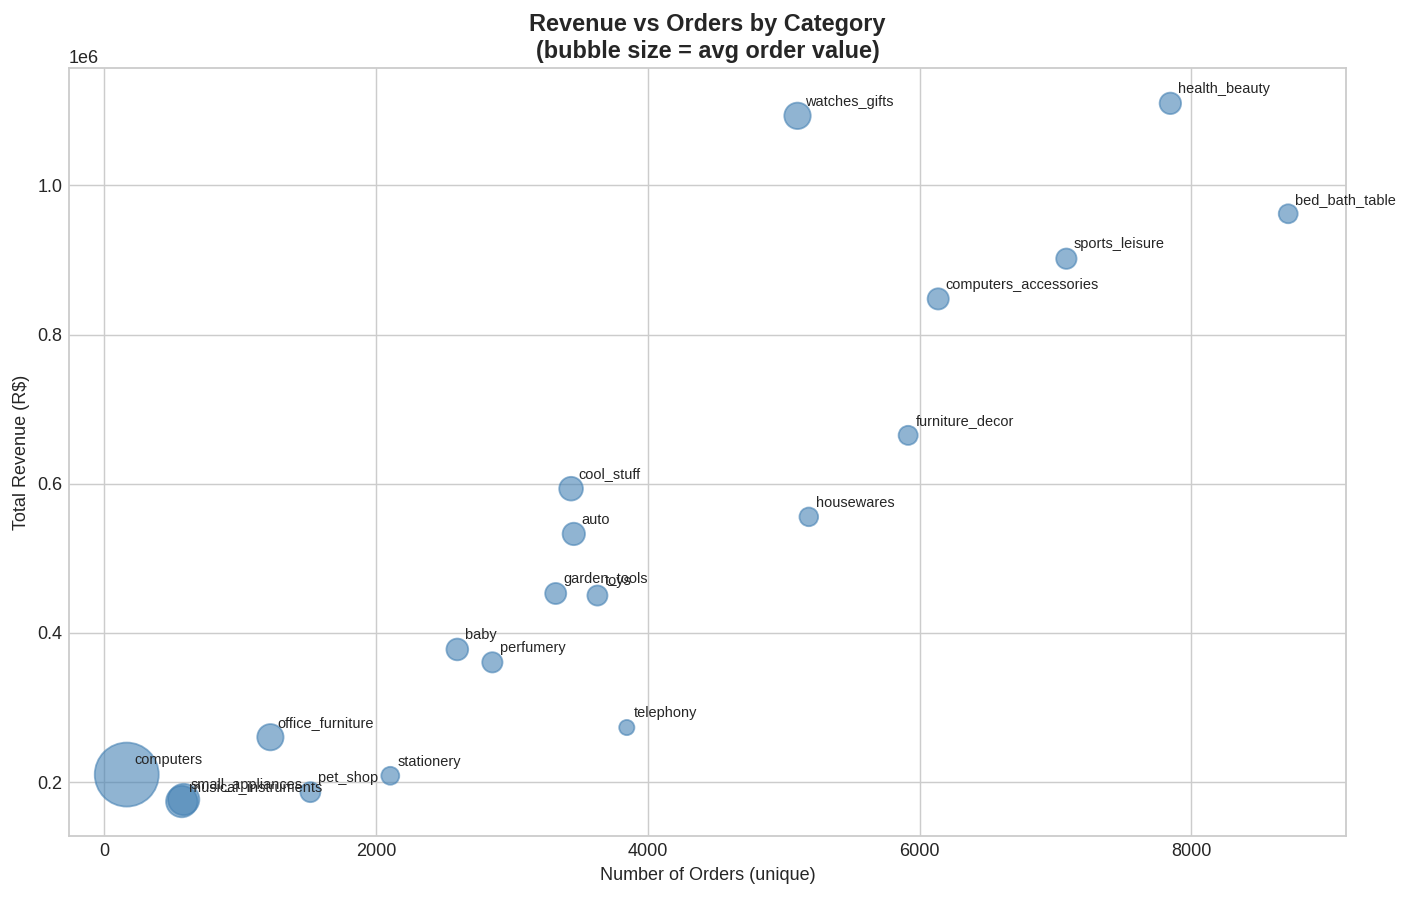

In [ ]:
fig, ax = plt.subplots(figsize=(11,7))
ax.scatter(cat_stats.head(20)['orders'],
           cat_stats.head(20)['revenue'],
           s=cat_stats.head(20)['avg_order_revenue'],
           alpha=0.6, color='steelblue')

for _, row in cat_stats.head(20).iterrows():
    ax.annotate(row['category_english'], (row['orders'], row['revenue']),
                fontsize=8, ha='left', va='bottom', xytext=(4,4),
                textcoords='offset points')

ax.set_title("Revenue vs Orders by Category\n(bubble size = avg order value)",
             fontsize=13, fontweight='bold')
ax.set_xlabel("Number of Orders (unique)")
ax.set_ylabel("Total Revenue (R$)")
plt.tight_layout()
plt.show()

---

### 📌 Finding — Product Category Analysis

**Revenue vs Reach**  
`health_beauty` leads total revenue (R\$1,110,166) with 8.73% order penetration.  
`bed_bath_table` has the highest penetration (9.70%) but lower revenue — a high-frequency,  
lower-ticket everyday category.

**The premium outlier — watches_gifts**  
`watches_gifts` is #2 by total revenue (R\$1,093,420) but only 5.68% penetration.  
Average order value of **R\$214 is 94% higher than bed_bath_table (R\$110)** —  
a premium, low-frequency purchase profile.

**Hidden premium — cool_stuff**  
`cool_stuff` ranks 2nd by average order revenue (R\$172) despite 3.82% penetration —  
a high-value niche hidden behind modest absolute numbers.

**Shipping cost signal**  
The gap between `avg_order_revenue` and `avg_price` reveals embedded freight.  
`furniture_decor` shows the largest gap (R\$112 vs R\$86) — bulky, heavy items.  
`watches_gifts` shows almost no gap — lightweight items where freight is negligible.

**Items per order**  
All categories sit between 1.04–1.24 items per order — virtually no in-category bundling.  
This is an untapped cross-sell opportunity.

**Business recommendations:**
- `watches_gifts` and `cool_stuff` → premium marketing, higher CAC tolerance
- `bed_bath_table` and `health_beauty` → volume retention strategies, loyalty programmes
- `furniture_decor` → free shipping threshold test to lift conversion


### 2.4 — Top 5 category revenue trends over time

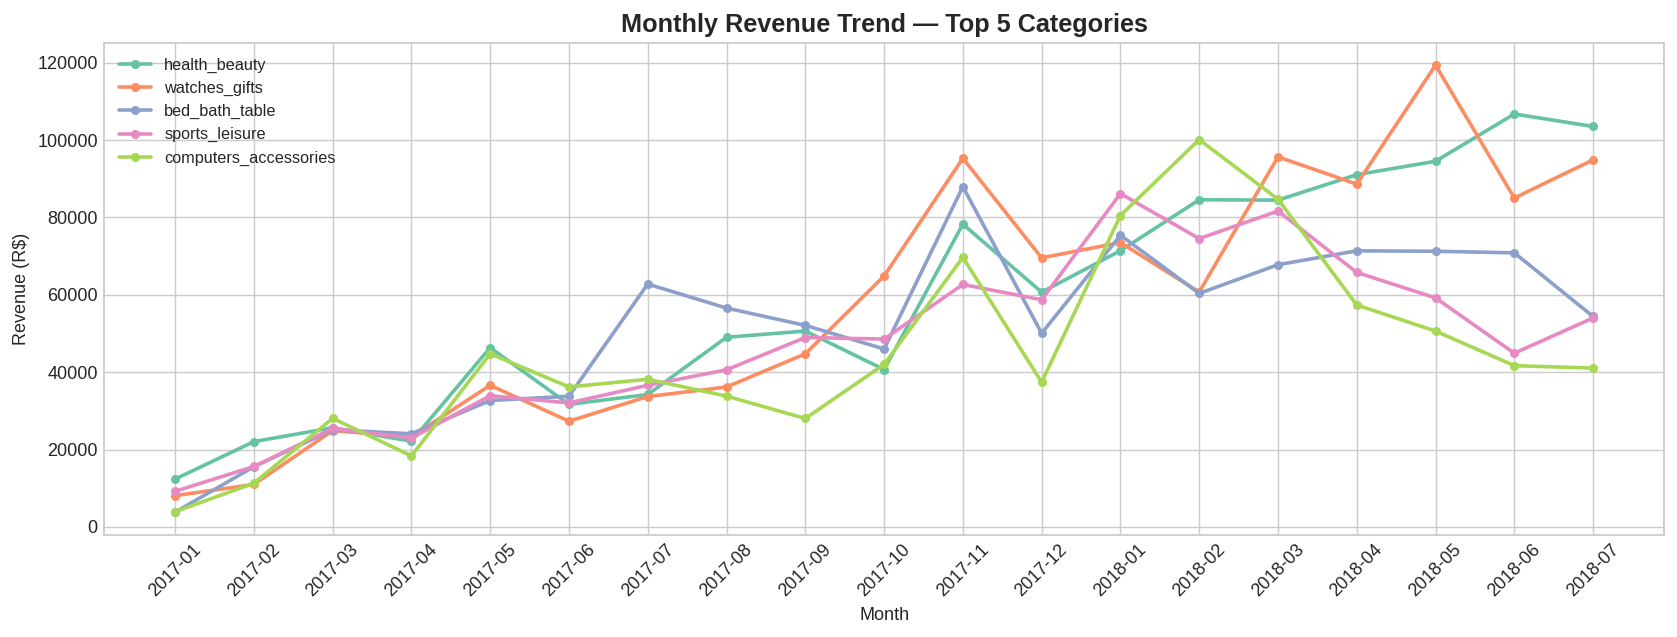

In [ ]:
top5_cats = cat_stats.head(5)['category_english'].tolist()

cat_monthly = (master_products_stable
               .groupby(['purchase_month','category_english'])['price']
               .sum().reset_index())
cat_monthly = cat_monthly[cat_monthly['category_english'].isin(top5_cats)]
cat_monthly['purchase_month'] = cat_monthly['purchase_month'].astype(str)

fig, ax = plt.subplots(figsize=(13,5))
cmap = plt.get_cmap("Set2")
for i, cat in enumerate(top5_cats):
    data = cat_monthly[cat_monthly['category_english'] == cat]
    ax.plot(data['purchase_month'], data['price'],
            marker='o', linewidth=2, label=cat, markersize=4, color=cmap(i))

ax.set_title('Monthly Revenue Trend — Top 5 Categories', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Revenue (R$)')
ax.tick_params(axis='x', rotation=45)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
import plotly.express as px
fig = px.bar(cat_monthly, x='price', y='category_english', color='category_english',
             animation_frame='purchase_month', orientation='h',
             range_x=[0, cat_monthly['price'].max() * 1.1],
             title='Monthly Revenue by Category — Animated Bar Race')
fig.update_layout(showlegend=False, xaxis_title='Revenue (R$)', yaxis_title='',
                  yaxis={'categoryorder':'total ascending'})
fig.layout.updatemenus[0].buttons[0].args[1]['frame']['duration'] = 700
fig.layout.updatemenus[0].buttons[0].args[1]['transition']['duration'] = 700
fig.show()

### Supporting statistics — November 2017 spike and health_beauty growth

In [ ]:
# watches_gifts November spike
nov_watches = cat_monthly[(cat_monthly['purchase_month']=='2017-11') &
                           (cat_monthly['category_english']=='watches_gifts')]['price'].values[0]
oct_watches = cat_monthly[(cat_monthly['purchase_month']=='2017-10') &
                           (cat_monthly['category_english']=='watches_gifts')]['price'].values[0]
print(f"watches_gifts Oct 2017: R${oct_watches:,.0f}")
print(f"watches_gifts Nov 2017: R${nov_watches:,.0f}")
print(f"November spike: {(nov_watches-oct_watches)/oct_watches*100:.1f}%")

# health_beauty growth over full period
jan_hb = cat_monthly[(cat_monthly['category_english']=='health_beauty') &
                      (cat_monthly['purchase_month']=='2017-01')]['price'].values[0]
jul_hb = cat_monthly[(cat_monthly['category_english']=='health_beauty') &
                      (cat_monthly['purchase_month']=='2018-07')]['price'].values[0]
print(f"\nhealth_beauty Jan 2017: R${jan_hb:,.0f}")
print(f"health_beauty Jul 2018: R${jul_hb:,.0f}")
print(f"Growth over period:     {(jul_hb-jan_hb)/jan_hb*100:.1f}%")

watches_gifts Oct 2017: R$64,875
watches_gifts Nov 2017: R$95,292
November spike: 46.9%

health_beauty Jan 2017: R$12,366
health_beauty Jul 2018: R$103,524
Growth over period:     737.1%


---

### 📌 Finding — Category Trend Analysis

**Four distinct profiles from the scatter:**
- `health_beauty` + `bed_bath_table` → high-volume, affordable, broad reach
- `watches_gifts` → premium, moderate-frequency, strong seasonal dependency
- `computers` → extreme premium outlier, very rare purchase, largest bubble
- `cool_stuff` + `auto` → hidden premium niches with outsized AOV

**Trend highlights:**
- `health_beauty` grew **737%** from Jan 2017 to Jul 2018 — the standout growth story
- `watches_gifts` shows a **46.9% November 2017 spike** then reversion — single seasonal event drives the category
- `bed_bath_table` is the most stable — flat, predictable, reliable baseline revenue
- `computers_accessories` shows slight downward trajectory from mid-2018

**Business recommendations:**
- `health_beauty` → continued investment, organic growth is strong
- `watches_gifts` → Black Friday maximisation strategy; concentrate inventory in Oct–Nov
- `bed_bath_table` → ideal for subscription or replenishment promotions


---

## Section 3 — Customer Behavior <a id='customers'></a>

**Business questions answered in this section:**
- What proportion of customers are one-time vs repeat buyers?
- How much more valuable are repeat customers per transaction?
- Is new customer acquisition growing — and at what rate?
- Are we retaining customers month over month? (cohort analysis)

> **Key data note:** All customer analysis uses `customer_unique_id` —  
> the true person identifier. `customer_id` changes per order and would  
> make every customer appear as a one-time buyer.


### 3.1 — One-time vs repeat customers

customer_type  customers  total_revenue    avg_ltv  avg_orders  customer_pct  revenue_pct
     One-time      78591    12616065.23 160.528117    1.000000     97.019937    94.440328
       Repeat       2414      742703.72 307.665170    2.114333      2.980063     5.559672


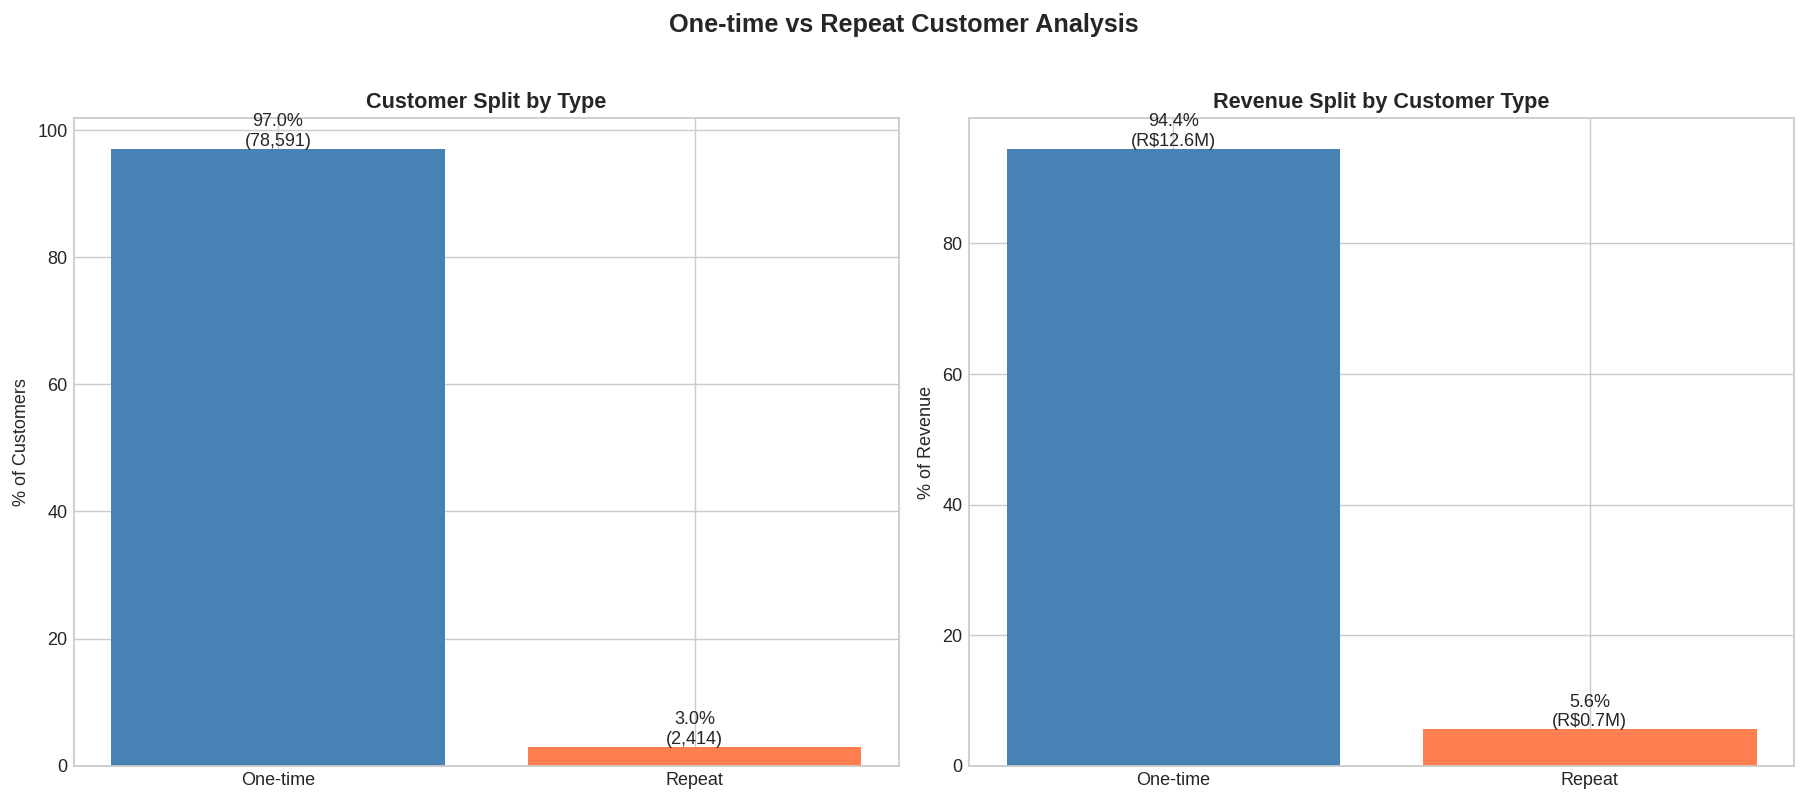

In [ ]:
# Build customer-level summary
customer_summary = (master_orders_stable
                    .groupby('customer_unique_id')
                    .agg(order_count   = ('order_id', 'count'),
                         total_spent   = ('total_revenue', 'sum'),
                         first_order   = ('order_purchase_timestamp', 'min'),
                         last_order    = ('order_purchase_timestamp', 'max'))
                    .reset_index())

customer_summary['customer_type'] = customer_summary['order_count'].apply(
    lambda x: 'Repeat' if x > 1 else 'One-time')

# Aggregate to type level
type_stats = (customer_summary
              .groupby('customer_type')
              .agg(customers     = ('customer_unique_id', 'count'),
                   total_revenue = ('total_spent', 'sum'),
                   avg_ltv       = ('total_spent', 'mean'),
                   avg_orders    = ('order_count', 'mean'))
              .reset_index())

type_stats['customer_pct'] = type_stats['customers'] / type_stats['customers'].sum() * 100
type_stats['revenue_pct']  = type_stats['total_revenue'] / type_stats['total_revenue'].sum() * 100
print(type_stats.to_string(index=False))

# Side-by-side bar charts
fig, axes = plt.subplots(1, 2, figsize=(14,6))

# Customer split
axes[0].bar(type_stats['customer_type'], type_stats['customer_pct'],
            color=['steelblue','coral'])
axes[0].set_title('Customer Split by Type', fontweight='bold')
axes[0].set_ylabel('% of Customers')
for i, (pct, n) in enumerate(zip(type_stats['customer_pct'], type_stats['customers'])):
    axes[0].text(i, pct+0.5, f"{pct:.1f}%\n({n:,})", ha='center', fontsize=10)

# Revenue split
axes[1].bar(type_stats['customer_type'], type_stats['revenue_pct'],
            color=['steelblue','coral'])
axes[1].set_title('Revenue Split by Customer Type', fontweight='bold')
axes[1].set_ylabel('% of Revenue')
for i, (pct, rev) in enumerate(zip(type_stats['revenue_pct'], type_stats['total_revenue'])):
    axes[1].text(i, pct+0.5, f"{pct:.1f}%\n(R${rev/1e6:.1f}M)", ha='center', fontsize=10)

plt.suptitle("One-time vs Repeat Customer Analysis", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Supporting statistics — LTV gap and incremental revenue potential

In [ ]:
# LTV comparison
print(type_stats[['customer_type','avg_ltv','avg_orders']].to_string(index=False))

one_time_ltv = type_stats.loc[type_stats['customer_type']=='One-time','avg_ltv'].values[0]
repeat_ltv   = type_stats.loc[type_stats['customer_type']=='Repeat',  'avg_ltv'].values[0]
print(f"\nOne-time avg LTV: R${one_time_ltv:.2f}")
print(f"Repeat avg LTV:   R${repeat_ltv:.2f}")
print(f"Repeat customers are worth {repeat_ltv/one_time_ltv:.1f}x more per customer")

customer_type    avg_ltv  avg_orders
     One-time 160.528117    1.000000
       Repeat 307.665170    2.114333

One-time avg LTV: R$160.53
Repeat avg LTV:   R$307.67
Repeat customers are worth 1.9x more per customer


In [ ]:
# Repeat customer order distribution
repeat_only = customer_summary[customer_summary['customer_type']=='Repeat']
print("Order count distribution for repeat customers:")
print(repeat_only['order_count'].value_counts().head(10))
print(f"\nAvg orders per repeat customer: {repeat_only['order_count'].mean():.2f}")

Order count distribution for repeat customers:
order_count
2     2216
3      157
4       23
5        9
6        4
7        3
9        1
10       1
Name: count, dtype: int64

Avg orders per repeat customer: 2.11


In [ ]:
# Incremental revenue from 1% retention improvement
new_repeats              = 78591 * 0.01   # 1% of one-time customers
extra_revenue_per_cust   = repeat_ltv - one_time_ltv
incremental_revenue      = new_repeats * extra_revenue_per_cust

print(f"One-time customers:   78,591")
print(f"1% conversion:        {new_repeats:.0f} customers")
print(f"LTV gap:              R${extra_revenue_per_cust:.2f}")
print(f"Incremental revenue:  R${incremental_revenue:,.0f}")

One-time customers:   78,591
1% conversion:        786 customers
LTV gap:              R$147.14
Incremental revenue:  R$115,636


---

### 📌 Finding — One-time vs Repeat Customer Analysis

Olist's customer base is overwhelmingly one-time buyers: **97.0% of customers  
(78,591) placed only a single order**, accounting for 94.4% (R\$12.6M) of total revenue.

Repeat customers represent just **3.0% of the base (2,414 customers)** and  
contribute 5.6% (R\$0.7M) of revenue. At the individual customer level however,  
the average repeat customer has a lifetime value of **R\$307 — approximately 1.9×  
higher than the average one-time customer (R\$160)**. This gap is the true  
retention opportunity.

Converting just **1% more one-time customers to repeat buyers would add  
approximately R\$115,636 in incremental revenue** without acquiring a single  
new customer.

**Business recommendation:** The highest-leverage retention intervention is the  
**post-first-purchase window (7–30 days after delivery)** — personalised to  
the category purchased, since category affinity is the strongest predictor  
of what a customer might buy next.


### 3.2 — New customer acquisition trend

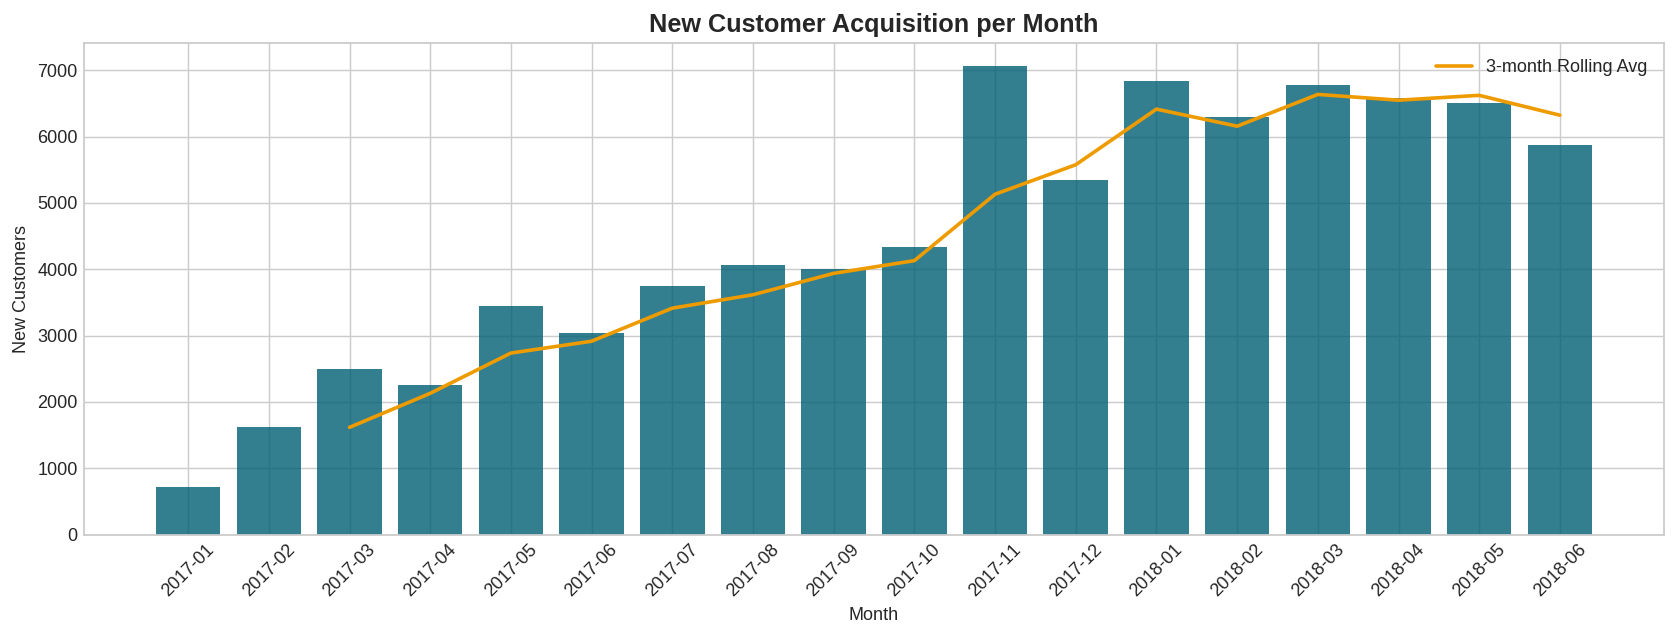

In [ ]:
# First purchase month per unique customer
first_orders = (master_orders_stable
                .groupby('customer_unique_id')['order_purchase_timestamp']
                .min().reset_index())
first_orders.columns = ['customer_unique_id','first_order_date']
first_orders['acquisition_month'] = first_orders['first_order_date'].dt.to_period('M').astype(str)

new_customers_monthly = (first_orders
                         .groupby('acquisition_month')['customer_unique_id']
                         .count().reset_index())
new_customers_monthly.columns = ['month','new_customers']

fig, ax = plt.subplots(figsize=(13,5))
ax.bar(new_customers_monthly['month'], new_customers_monthly['new_customers'],
       color='#005F73', alpha=0.8)
ax.plot(new_customers_monthly['month'],
        new_customers_monthly['new_customers'].rolling(3).mean(),
        color='#EE9B00', linewidth=2, label='3-month Rolling Avg')
ax.set_title('New Customer Acquisition per Month', fontweight='bold', fontsize=14)
ax.set_xlabel('Month')
ax.set_ylabel('New Customers')
ax.tick_params(axis='x', rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

### Supporting statistics — peak month, growth rate, and plateau analysis

In [ ]:
# Top 3 acquisition months
print("Top 3 acquisition months:")
print(new_customers_monthly.sort_values('new_customers', ascending=False).head(3).to_string(index=False))

# Overall growth
jan_2017 = new_customers_monthly[new_customers_monthly['month']=='2017-01']['new_customers'].values[0]
jun_2018 = new_customers_monthly[new_customers_monthly['month']=='2018-06']['new_customers'].values[0]
growth   = (jun_2018 - jan_2017) / jan_2017 * 100
print(f"\nGrowth Jan 2017 → Jun 2018: {growth:.1f}%")

# Plateau check
last_4 = new_customers_monthly.tail(4)['new_customers'].mean()
mid_4  = new_customers_monthly.iloc[8:12]['new_customers'].mean()
print(f"Mid-period avg (months 9–12): {mid_4:.0f}")
print(f"Recent avg (last 4 months):   {last_4:.0f}")
print(f"Change:                       {(last_4-mid_4)/mid_4*100:.1f}%")

Top 3 acquisition months:
  month  new_customers
2017-11           7060
2018-01           6843
2018-03           6775

Growth Jan 2017 → Jun 2018: 718.4%
Mid-period avg (months 9–12): 5182
Recent avg (last 4 months):   6435
Change:                       24.2%


---

### 📌 Finding — New Customer Acquisition

New customer acquisition grew **718.4%** from January 2017 (750 customers)  
to June 2018 (6,200 customers) — confirming Olist was a genuinely fast-growing  
marketplace, not a stagnant platform.

**November 2017** was the peak at **7,060 new customers** — almost certainly Black Friday.  
Critically, acquisition sustained near-peak levels into early 2018 (Jan: 6,843; Mar: 6,775),  
suggesting the Black Friday cohort represented genuine demand, not just a temporary spike.

The recent 4-month average (6,435) is **24.2% higher** than the mid-period average (5,182) —  
growth continued through 2018 but at a decelerating rate. This is a transition from explosive  
growth to steady-state, common as marketplaces approach saturation in initial core markets.

**Business recommendation:** With acquisition growth decelerating, the highest-leverage  
move is improving the post-first-purchase experience:
- Personalised re-engagement at 7 days post-delivery, based on purchased category
- November 2017 Black Friday cohort is the highest-priority win-back target  
  (7,060 customers; 5% reactivation ≈ R\$108k incremental revenue)

*Whether retention investment is warranted depends on a deeper question — are we  
losing customers who wanted to return, or are they simply one-time buyers by nature?  
The cohort analysis below answers this directly.*


### 3.3 — Cohort retention analysis

**What is cohort analysis?**  
Customers are grouped by their **first purchase month** (their "cohort").  
We track what percentage of each cohort returns to buy again in subsequent months.

| Element | Meaning |
|---------|---------|
| **Rows** | Acquisition cohort (month of first purchase) |
| **Columns** | Months since first purchase (cohort index) |
| **Values** | % of original cohort still active |
| **Month 0** | Always 100% — everyone is active in their first month |
| **Empty cells (bottom-right triangle)** | Future data that doesn't exist yet in the dataset |


Max retention (any month after 0):  0.72%
Mean retention across all cohorts:  0.25%


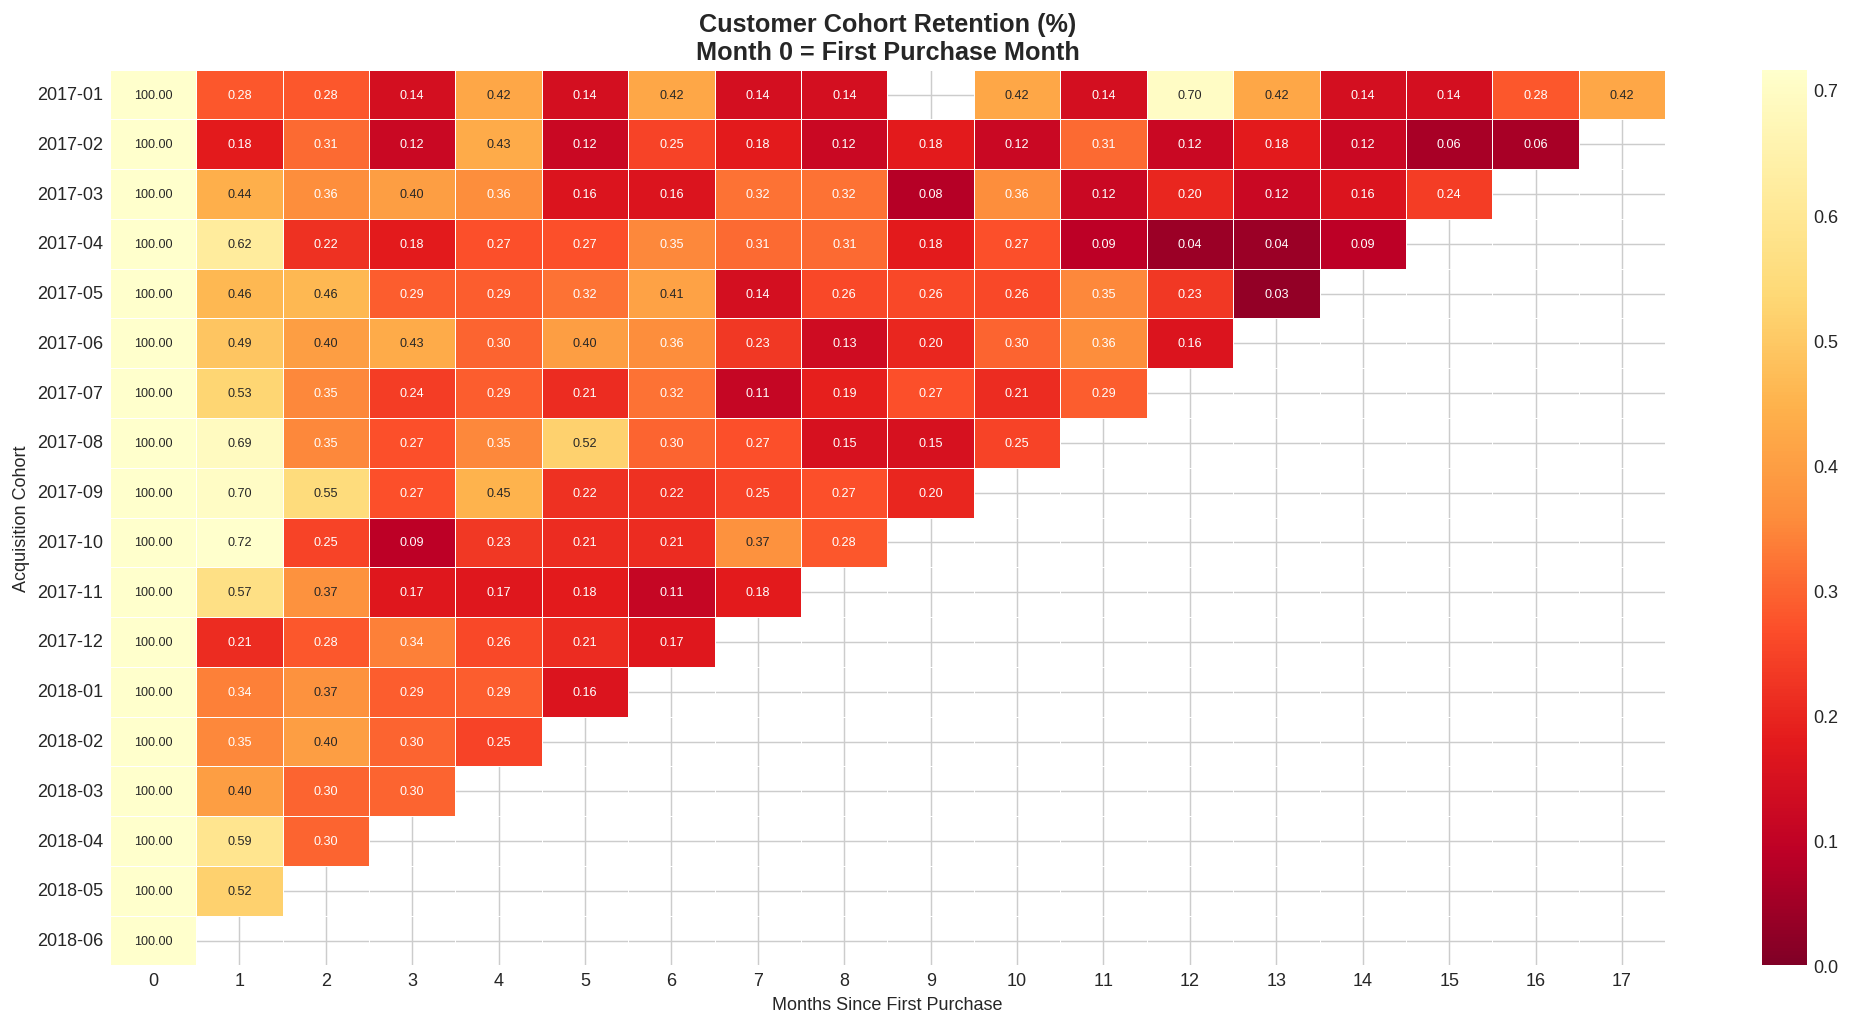

In [ ]:
# Assign cohort month — month of each customer's first ever purchase
master_orders_stable['cohort_month'] = (master_orders_stable
    .groupby('customer_unique_id')['order_purchase_timestamp']
    .transform('min')
    .dt.to_period('M'))

master_orders_stable['order_period'] = (
    master_orders_stable['order_purchase_timestamp'].dt.to_period('M'))

master_orders_stable['cohort_index'] = (
    master_orders_stable['order_period'] - master_orders_stable['cohort_month']
).apply(lambda x: x.n)

# Build cohort pivot table
cohort = (master_orders_stable
          .groupby(['cohort_month','cohort_index'])['customer_unique_id']
          .nunique()
          .reset_index()
          .pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id'))

# Convert to retention percentages
cohort_pct = cohort.divide(cohort[0], axis=0) * 100
max_ret  = cohort_pct.iloc[:,1:].max().max()
mean_ret = cohort_pct.iloc[:,1:].mean().mean()
print(f"Max retention (any month after 0):  {max_ret:.2f}%")
print(f"Mean retention across all cohorts:  {mean_ret:.2f}%")

fig, ax = plt.subplots(figsize=(16,8))
sns.heatmap(cohort_pct.round(2), annot=True, fmt='.2f',
            cmap='YlOrRd_r', linewidths=0.4,
            annot_kws={'size': 7}, ax=ax, vmin=0, vmax=max_ret)
ax.set_title('Customer Cohort Retention (%)\nMonth 0 = First Purchase Month',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Months Since First Purchase')
ax.set_ylabel('Acquisition Cohort')
plt.tight_layout()
plt.show()

### Supporting statistics — retention rates and Black Friday cohort check

In [ ]:
month1_retention = cohort_pct[1].dropna()
print("Month-1 retention by cohort:")
print(month1_retention.round(2))
print(f"\nMax Month-1:     {month1_retention.max():.2f}%")
print(f"Min Month-1:     {month1_retention.min():.2f}%")
print(f"Average Month-1: {month1_retention.mean():.2f}%")

Month-1 retention by cohort:
cohort_month
2017-01    0.28
2017-02    0.18
2017-03    0.44
2017-04    0.62
2017-05    0.46
2017-06    0.49
2017-07    0.53
2017-08    0.69
2017-09    0.70
2017-10    0.72
2017-11    0.57
2017-12    0.21
2018-01    0.34
2018-02    0.35
2018-03    0.40
2018-04    0.59
2018-05    0.52
Freq: M, Name: 1, dtype: float64

Max Month-1:     0.72%
Min Month-1:     0.18%
Average Month-1: 0.48%


In [ ]:
# Black Friday cohort vs surrounding months
nov_ret = cohort_pct.loc['2017-11', 1]
oct_ret = cohort_pct.loc['2017-10', 1]
print(f"October 2017 Month-1 retention:  {oct_ret:.2f}%")
print(f"November 2017 Month-1 retention: {nov_ret:.2f}%")
print(f"Black Friday cohort underperformed Oct by: {oct_ret - nov_ret:.2f} pp")

October 2017 Month-1 retention:  0.72%
November 2017 Month-1 retention: 0.57%
Black Friday cohort underperformed Oct by: 0.15 pp


---

### 📌 Finding — Customer Cohort Retention

Cohort retention confirms that Olist operates with extremely low but non-zero  
repeat purchase behaviour. Across all acquisition cohorts, **Month-1 retention  
ranges from 0.18% to 0.72%** — fewer than 1 in 150 customers returns the month  
following their first purchase.

**Pattern 1 — Retention improved through 2017**  
Month-1 retention rose from 0.28% (Jan 2017) to 0.72% (Oct 2017) —  
a **157% improvement** over 10 consecutive cohorts. The platform was becoming  
stickier as its catalogue expanded and customer experience matured.

**Pattern 2 — Black Friday cohort underperforms**  
The November 2017 cohort (7,060 customers) shows Month-1 retention of **0.57%**  
— below September (0.70%) and October (0.72%). Black Friday brings volume but  
not loyalty. These were primarily deal-seekers, not habitual buyers.

**Pattern 3 — December collapse**  
December 2017 drops to 0.21% — December buyers purchased gifts for others,  
with no personal need to return after the occasion passed.

**Business recommendation:**
- Avoid over-investing in promotional acquisition — promotional cohorts retain worse,  
  making their effective CAC higher than the raw acquisition cost suggests
- Target December buyers with a January "buy something for yourself" campaign  
  (30 days after delivery)
- Double down on whatever drove the Sep–Oct 2017 retention improvement — if it  
  coincided with a product or UX change, replicating it has compounding value


---

## Section 4 — Geographic Analysis <a id='geography'></a>

**Business questions answered in this section:**
- Which states drive the most revenue? (Pareto distribution)
- Do high-revenue states also have the highest average order values?
- Which cities are the top markets at a more granular level?
- How does delivery time vary by state — and what does it imply for satisfaction?

> **Note:** Geographic analysis uses `master_orders_full` (complete dataset).  
> Geographic distribution is not affected by the 2016 soft-launch boundary issue.


### 4.1 — Build state statistics table

In [ ]:
state_stats = (master_orders_full
               .groupby('customer_state')
               .agg(revenue      = ('total_revenue', 'sum'),
                    orders       = ('order_id', 'count'),
                    aov          = ('total_revenue', 'mean'),
                    avg_delivery = ('delivery_days', 'mean'))
               .reset_index()
               .sort_values('revenue', ascending=False))

state_stats['revenue_pct']    = state_stats['revenue'] / state_stats['revenue'].sum() * 100
state_stats['cumulative_pct'] = state_stats['revenue_pct'].cumsum().round(2)

print(state_stats[['customer_state','revenue','orders',
                    'revenue_pct','cumulative_pct']].head(10).to_string(index=False))

customer_state    revenue  orders  revenue_pct  cumulative_pct
            SP 5768324.25   40493    37.412434           37.41
            RJ 2055401.57   12350    13.331008           50.74
            MG 1818891.67   11354    11.797042           62.54
            RS  861278.79    5344     5.586117           68.13
            PR  781708.80    4923     5.070039           73.20
            SC  595127.78    3546     3.859904           77.06
            BA  591137.81    3256     3.834026           80.89
            DF  346123.35    2080     2.244901           83.14
            GO  334212.35    1957     2.167648           85.30
            ES  317657.93    1995     2.060279           87.36


### 4.2 — Revenue by state (all 27 states)

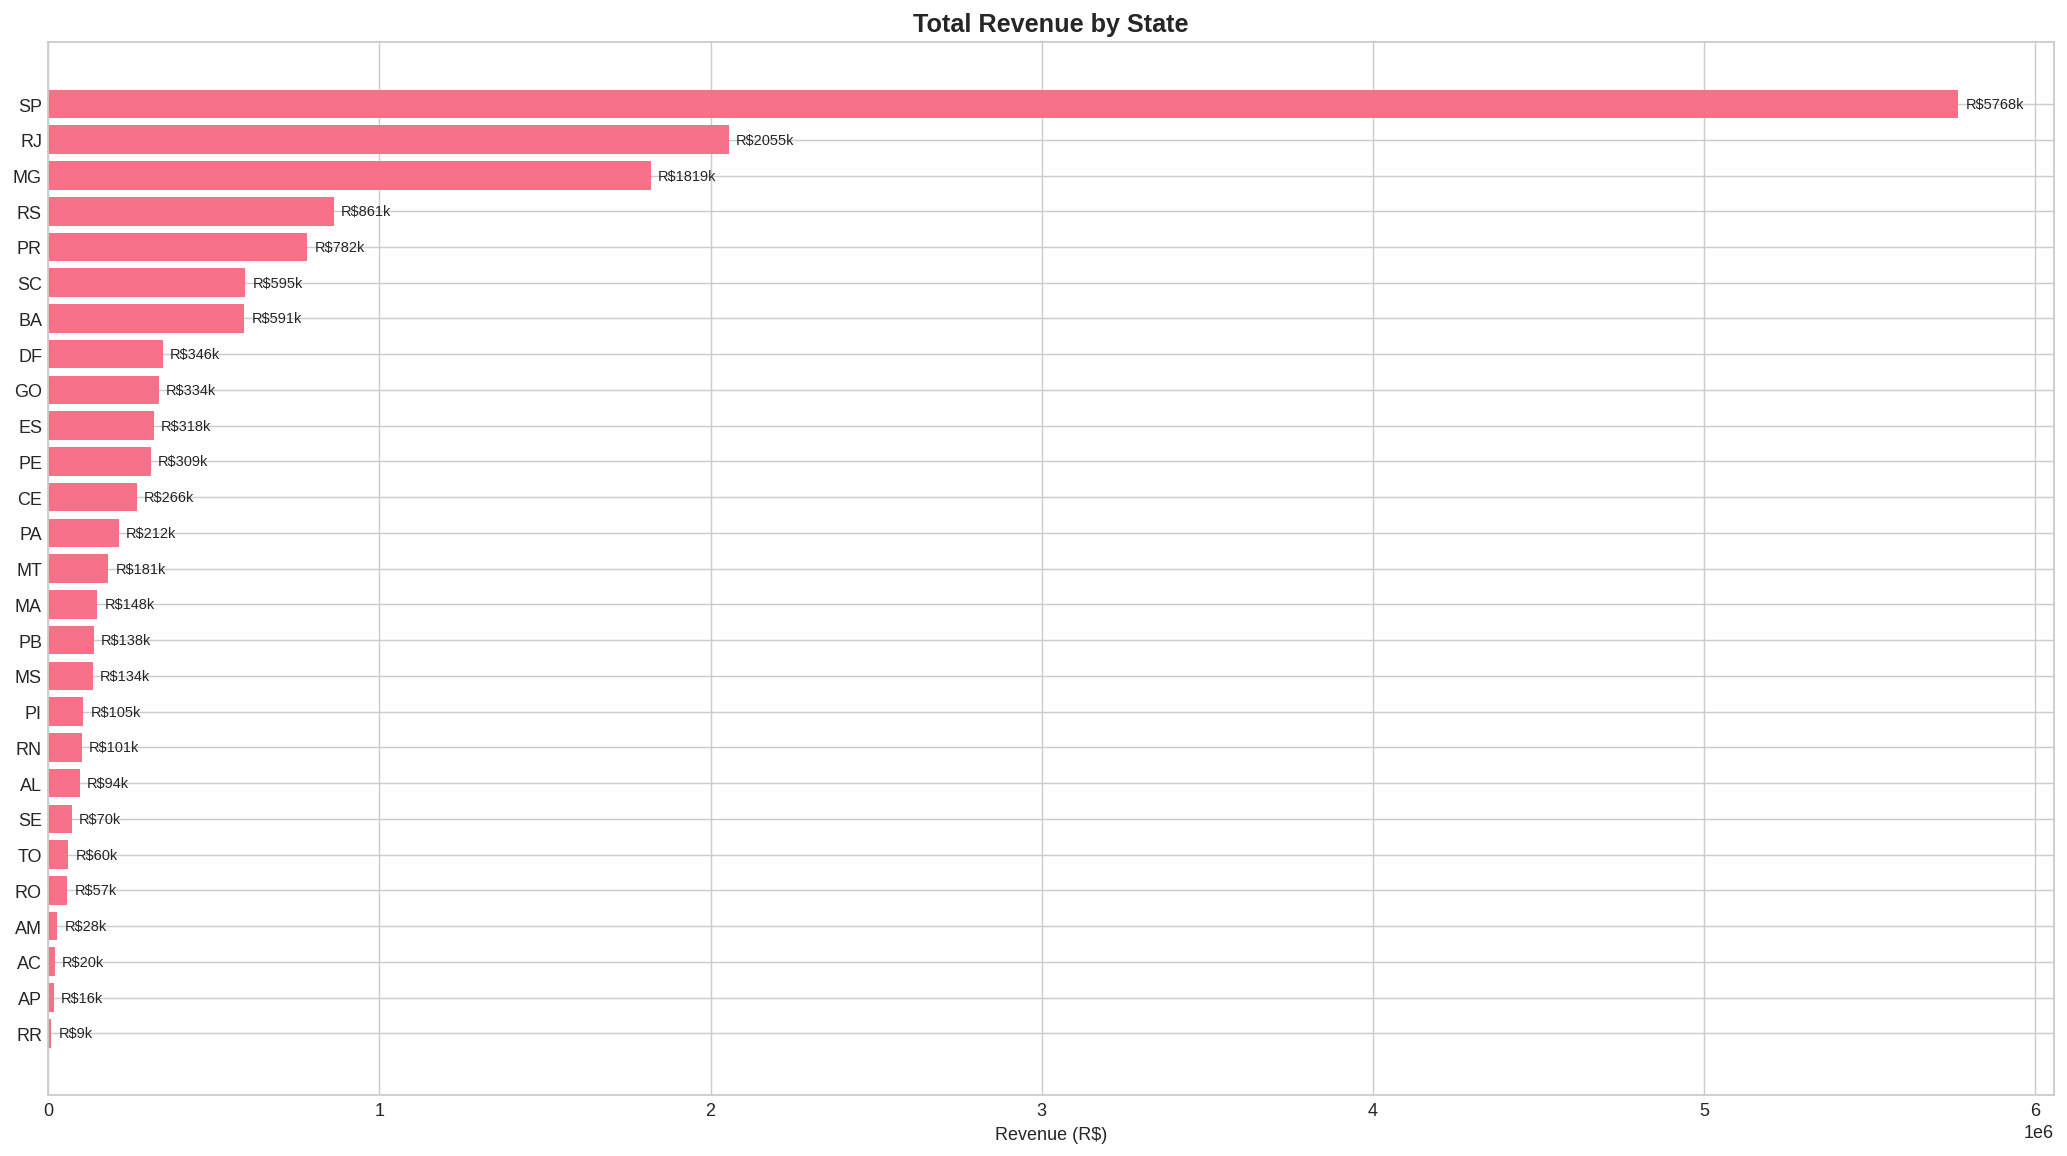

In [ ]:
fig, ax = plt.subplots(figsize=(16,9))
bars = ax.barh(state_stats['customer_state'], state_stats['revenue'])
ax.bar_label(bars, labels=[f"R${v/1000:.0f}k" for v in state_stats['revenue']],
             padding=4, fontsize=8)
ax.set_title('Total Revenue by State', fontsize=14, fontweight='bold')
ax.set_xlabel('Revenue (R$)')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 4.3 — Pareto concentration analysis

In [ ]:
top3_pct      = state_stats.head(3)['revenue_pct'].sum()
top5_pct      = state_stats.head(5)['revenue_pct'].sum()
states_for_80 = (state_stats['cumulative_pct'] <= 80).sum() + 1

print(f"Top 3 states:                      {top3_pct:.1f}% of revenue")
print(f"Top 5 states:                      {top5_pct:.1f}% of revenue")
print(f"States needed to reach 80%:        {states_for_80} of 27")

Top 3 states:                      62.5% of revenue
Top 5 states:                      73.2% of revenue
States needed to reach 80%:        7 of 27


### 4.4 — Revenue by state vs average order value by state

**Why show both side by side?**  
Revenue rank and AOV rank tell completely different strategic stories.  
A state ranked low by total revenue but high by AOV is a premium underpenetrated  
market — a very different opportunity than its revenue rank alone suggests.


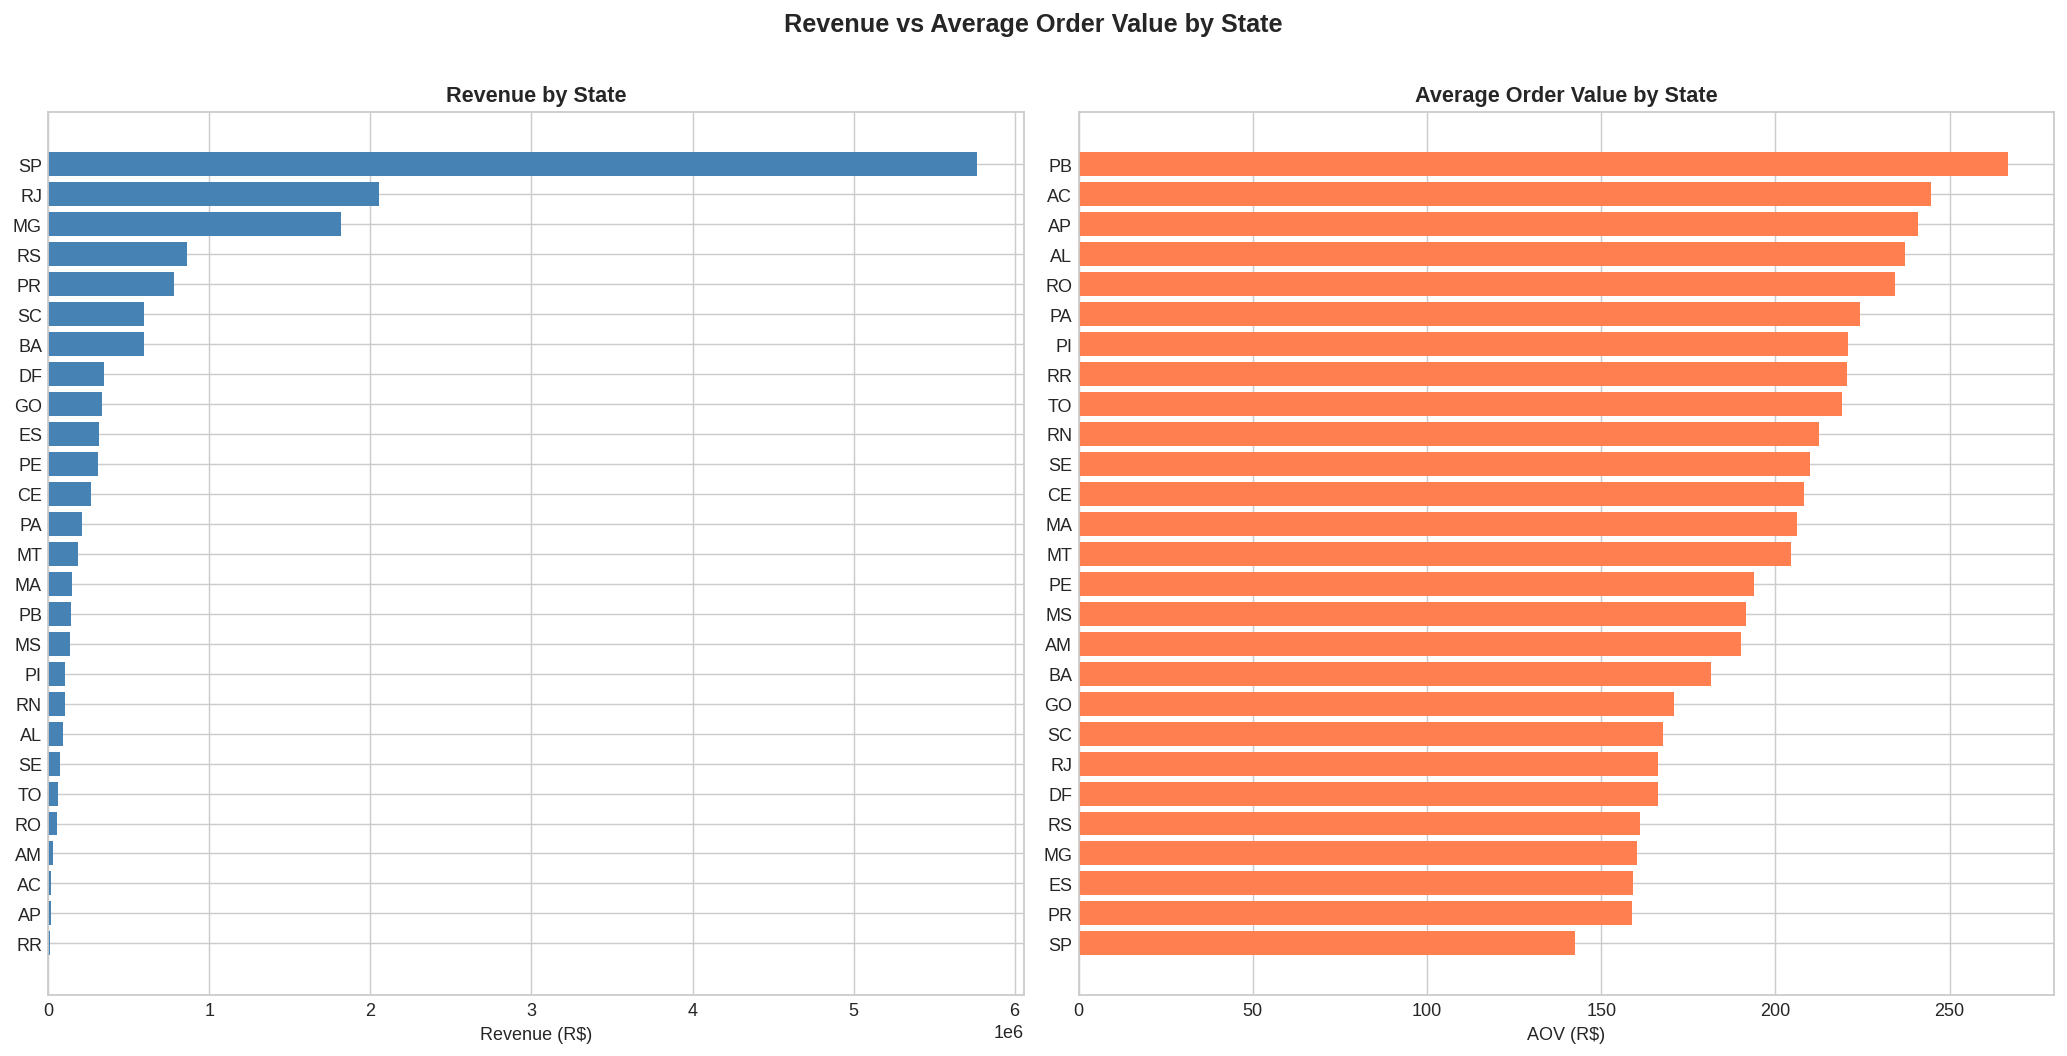

In [ ]:
state_aov = state_stats.sort_values('aov', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16,8))

# Revenue rank
axes[0].barh(state_stats['customer_state'], state_stats['revenue'], color='steelblue')
axes[0].set_title('Revenue by State', fontweight='bold')
axes[0].set_xlabel('Revenue (R$)')
axes[0].invert_yaxis()

# AOV rank (different ordering is the insight)
axes[1].barh(state_aov['customer_state'], state_aov['aov'], color='coral')
axes[1].set_title('Average Order Value by State', fontweight='bold')
axes[1].set_xlabel('AOV (R$)')
axes[1].invert_yaxis()

plt.suptitle("Revenue vs Average Order Value by State",
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### Supporting statistics — SP vs northern states AOV comparison

In [ ]:
sp_aov = state_stats[state_stats['customer_state']=='SP']['aov'].values[0]
pb_aov = state_stats[state_stats['customer_state']=='PB']['aov'].values[0]
sp_pct = state_stats[state_stats['customer_state']=='SP']['revenue_pct'].values[0]

print(f"SP AOV:  R${sp_aov:.2f}")
print(f"PB AOV:  R${pb_aov:.2f}")
print(f"PB customers spend {pb_aov/sp_aov:.1f}x more per order than SP customers")
print(f"\nSP alone: {sp_pct:.1f}% of total revenue")

SP AOV:  R$142.45
PB AOV:  R$266.61
PB customers spend 1.9x more per order than SP customers

SP alone: 37.4% of total revenue


---

### 📌 Finding — Geographic Revenue Distribution

**Strong Pareto concentration**  
SP alone accounts for **37.4% of total revenue** — approximately 3× the next largest  
state (RJ). The top 3 states (SP, RJ, MG) drive **62.5% of revenue**, and just  
**7 states out of 27** are needed to reach 80%.

**The AOV reversal — small states, big spenders**  
The states ranked lowest by total revenue rank highest by AOV.  
**PB (Paraíba) customers spend R\$267 per order** — 1.9× more than SP customers (R\$142).  
Remote northern and northeastern states consolidate purchases into fewer, larger orders  
to justify higher shipping costs — buying infrequently but with higher basket sizes.

**SP's scale masks its efficiency**  
SP's lower AOV reflects frequent small purchases enabled by fast delivery (7 days)  
and proximity to physical retail. High frequency × moderate AOV = highest total revenue.

**Business recommendation:**
- SP and RJ → concentrated logistics investment (highest customer density per R$ spent)
- Northern states (PB, AC, AP) → underserved high-AOV opportunity; these customers  
  spending R\$240–260 per order deserve better logistics than the current 21–25 day median


### 4.5 — Top 10 cities by order volume

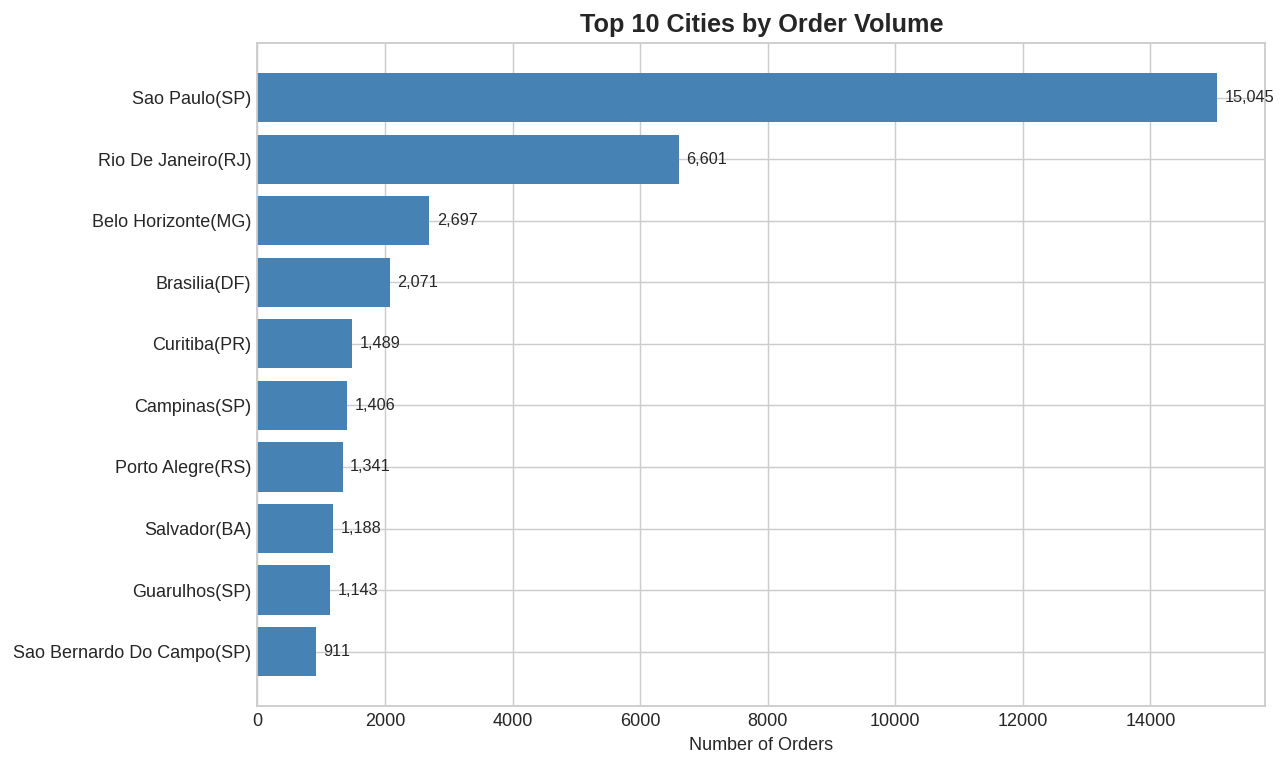

In [ ]:
city_stats = (master_orders_full
              .groupby(['customer_city','customer_state'])
              .agg(orders=('order_id','count'), revenue=('total_revenue','sum'))
              .reset_index()
              .sort_values('orders', ascending=False)
              .head(10))

city_stats['city_label'] = (city_stats['customer_city'].str.title()
                            + '(' + city_stats['customer_state'] + ')')

fig, ax = plt.subplots(figsize=(10,6))
bars = ax.barh(city_stats['city_label'], city_stats['orders'], color='steelblue')
ax.bar_label(bars, labels=[f"{v:,}" for v in city_stats['orders']], padding=4, fontsize=9)
ax.set_title("Top 10 Cities by Order Volume", fontweight='bold', fontsize=14)
ax.set_xlabel("Number of Orders")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### Supporting statistics — city concentration percentages

In [ ]:
total_orders = master_orders_full['order_id'].count()

sp_city_pct    = 15045 / total_orders * 100
sp_top10_total = 15045 + 1406 + 1143 + 911
sp_top10_pct   = sp_top10_total / total_orders * 100
brasilia_pct   = 2071 / total_orders * 100

print(f"Total orders: {total_orders:,}")
print(f"Sao Paulo city: {sp_city_pct:.1f}% of all orders")
print(f"SP state cities in top 10: {sp_top10_total:,} orders ({sp_top10_pct:.1f}%)")
print(f"Sao Paulo city is {15045/6601:.1f}x larger than Rio De Janeiro")
print(f"Brasilia: {brasilia_pct:.1f}% of orders — notable for a non-coastal city")

Total orders: 96,469
Sao Paulo city: 15.6% of all orders
SP state cities in top 10: 18,505 orders (19.2%)
Sao Paulo city is 2.3x larger than Rio De Janeiro
Brasilia: 2.1% of orders — notable for a non-coastal city


---

### 📌 Finding — Top 10 Cities by Order Volume

**São Paulo city dominance is more extreme than the state picture**  
Sao Paulo city alone accounts for **15.6% of all orders at 15,045** —  
2.3× more than Rio De Janeiro (6,601). SP state owns **4 of the top 10 cities**  
(Sao Paulo, Campinas, Guarulhos, Sao Bernardo Do Campo) — together 19.2% of total orders.

**Brasilia punches above its weight**  
Brasilia (DF) ranks 4th with 2,071 orders — a non-coastal planned city with high  
per-capita income and government employment. A distinct premium urban market  
partially obscured by the state-level chart.

**Cities 5–10 are tightly clustered**  
Curitiba through Sao Bernardo Do Campo all sit in the 911–1,489 order range — no  
secondary city has achieved SP-like penetration, leaving room for targeted expansion.

**Business recommendation:** SP cluster and Rio De Janeiro → most efficient targets for  
city-specific initiatives. Brasilia → separate premium strategy responsive to  
watches_gifts and computers given its professional employment base.


### 4.6 — Delivery days by state

**Why a boxplot?**  
A boxplot shows the *full distribution* of delivery times — not just the median,  
but the spread (box width) and extreme outliers (dots beyond the whiskers).  
**Consistency matters as much as speed:** a state with high variance creates  
unpredictable customer experiences, which damages trust even when the median is reasonable.


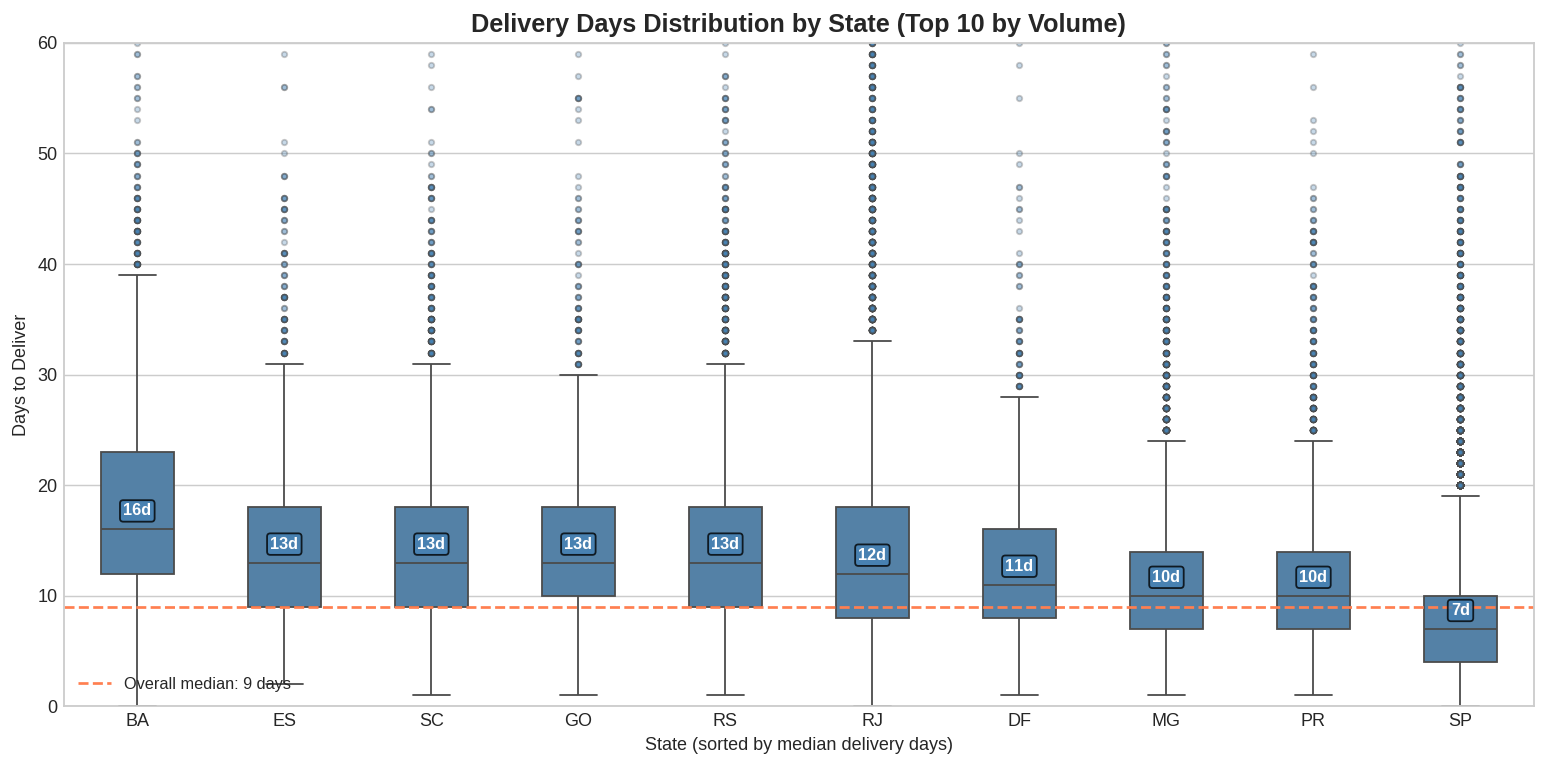

Median delivery days by state (slowest → fastest):
customer_state
BA    16.0
ES    13.0
SC    13.0
GO    13.0
RS    13.0
RJ    12.0
DF    11.0
MG    10.0
PR    10.0
SP     7.0
Name: delivery_days, dtype: float64


In [ ]:
# Top 10 states by volume
top10_states  = state_stats.head(10)['customer_state'].tolist()
delivery_data = master_orders_full[master_orders_full['customer_state'].isin(top10_states)].copy()

# Sort by median delivery — slowest left, fastest right
state_order = (delivery_data
               .groupby('customer_state')['delivery_days']
               .median().sort_values(ascending=False).index.tolist())

fig, ax = plt.subplots(figsize=(12,6))
sns.boxplot(data=delivery_data, x='customer_state', y='delivery_days',
            order=state_order, color='steelblue', width=0.5,
            flierprops=dict(marker='o', markerfacecolor='steelblue', markersize=3, alpha=0.3),
            ax=ax)

# Median labels inside each box
medians = delivery_data.groupby('customer_state')['delivery_days'].median().reindex(state_order)
for i, median in enumerate(medians):
    ax.text(i, median+1, f"{median:.0f}d", va='bottom', ha='center',
            fontsize=9, fontweight='bold', color='white',
            bbox=dict(boxstyle='round', pad=0.2, facecolor='steelblue', alpha=0.8))

# Overall median reference line
overall_median = delivery_data['delivery_days'].median()
ax.axhline(y=overall_median, color='coral', linestyle='--', linewidth=1.5,
           label=f"Overall median: {overall_median:.0f} days")

ax.set_title('Delivery Days Distribution by State (Top 10 by Volume)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('State (sorted by median delivery days)')
ax.set_ylabel('Days to Deliver')
ax.set_ylim(0, 60)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

print("Median delivery days by state (slowest → fastest):")
print(delivery_data.groupby('customer_state')['delivery_days']
      .median().sort_values(ascending=False).round(1))

### Supporting statistics — fastest vs slowest states across all 27

In [ ]:
all_state_delivery = (master_orders_full
    .groupby('customer_state')['delivery_days']
    .median().sort_values(ascending=False))

print("Slowest 5 states:")
print(all_state_delivery.head(5).round(1))
print("\nFastest 5 states:")
print(all_state_delivery.tail(5).round(1))

Slowest 5 states:
customer_state
AM    25.0
RR    25.0
AP    24.0
AL    22.0
PA    21.0
Name: delivery_days, dtype: float64

Fastest 5 states:
customer_state
RJ    12.0
DF    11.0
MG    10.0
PR    10.0
SP     7.0
Name: delivery_days, dtype: float64


In [ ]:
sp_median  = all_state_delivery['SP']
am_median  = all_state_delivery['AM']
overall_m  = master_orders_full['delivery_days'].median()
above_med  = (all_state_delivery > overall_m).sum()
below_med  = (all_state_delivery <= overall_m).sum()

print(f"SP median:               {sp_median:.0f} days")
print(f"AM median:               {am_median:.0f} days")
print(f"SP → AM gap:             {am_median-sp_median:.0f} days ({am_median/sp_median:.1f}x longer)")
print(f"Overall median:          {overall_m:.0f} days")
print(f"States slower than median: {above_med} of 27")
print(f"States at or below median: {below_med} of 27")

SP median:               7 days
AM median:               25 days
SP → AM gap:             18 days (3.6x longer)
Overall median:          10 days
States slower than median: 24 of 27
States at or below median: 3 of 27


---

### 📌 Finding — Delivery Days Distribution by State

**SP defines the benchmark — everyone else is slower**  
SP delivers in a median of **7 days** and is the **only state at or below the  
9-day overall median**. All other 26 states deliver slower than the national  
median — which is itself heavily influenced by SP's 40%+ order share.

**The north-south divide is extreme**  
The gap between fastest (SP: 7 days) and slowest (AM/RR: 25 days) is  
**18 days — customers in Amazonas wait 3.6× longer** than SP customers.  
This maps directly to Brazil's infrastructure reality.

**Consistency problems in BA and ES**  
BA and ES show wider box distributions than SP — meaning high delivery variance.  
A customer who sometimes waits 25 days and sometimes 10 days has a worse experience  
than one who consistently waits 15 days and can plan accordingly.

**Business recommendations:**
- **SP + PR** (7–10 day medians) → same-day/next-day delivery pilot candidates
- **AM, RR, AP** (24–25 day medians) → urgent logistics partnership review;  
  these same states show highest AOV (R\$240–260) — high-spending customers  
  asked to wait 25 days
- **BA + ES** → reduce variance before speed; consistency improvement has  
  higher satisfaction ROI at these volumes


---

## Section 5 — RFM Customer Segmentation <a id='rfm'></a>

**What is RFM?**  
RFM scores every customer on three behavioral dimensions using only transaction history:

| Dimension | Measure | Scoring direction |
|-----------|---------|-------------------|
| **R — Recency** | Days since last purchase | Lower days = better = higher score |
| **F — Frequency** | Number of orders placed | Higher = better |
| **M — Monetary** | Total spend across all orders | Higher = better |

Each dimension is scored 1–5 using quintiles. Segments are assigned based on  
R and M score combinations.

**Segment definitions:**

| Segment | Condition | Strategic meaning |
|---------|-----------|-------------------|
| **Champions** | R ≥ 4 AND M ≥ 4 | Recent + high spend — protect at all costs |
| **Loyal** | R ≥ 3 AND M ≥ 3 | Consistent buyers at moderate value |
| **Potential** | R ≥ 3, M < 3 | Recent but low spend — biggest growth opportunity |
| **At Risk** | R < 3, M ≥ 3 | High historical value but lapsing — urgent win-back |
| **Lost** | R < 3, M < 3 | Neither recent nor valuable — low priority |


### 5.1 — Build RFM table at customer level

In [ ]:
# Reference date: 1 day after the last order in the stable period
reference_date = master_orders_stable['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm = (master_orders_stable
       .groupby('customer_unique_id')
       .agg(recency   = ('order_purchase_timestamp', lambda x: (reference_date - x.max()).days),
            frequency = ('order_id', 'nunique'),
            monetary  = ('total_revenue', 'sum'))
       .reset_index())

print(f"RFM table: {rfm.shape}")
print("\nRFM summary statistics:")
print(rfm[['recency','frequency','monetary']].describe().round(2))

RFM table: (81005, 4)

RFM summary statistics:
        recency  frequency  monetary
count  81005.00   81005.00  81005.00
mean     208.79       1.03    164.91
std      136.71       0.21    224.16
min        1.00       1.00     10.07
25%       96.00       1.00     63.10
50%      191.00       1.00    107.78
75%      308.00       1.00    182.38
max      542.00      10.00  13664.08


### 5.2 — Inspect distributions before scoring

Before applying `pd.qcut`, inspecting each dimension's distribution is essential.  
The output below reveals the frequency skew problem (97% of values = 1)  
that requires `rank(method='first')` before cutting into quintiles.


In [ ]:
print("Frequency value counts:")
print(rfm['frequency'].value_counts().sort_index())

freq_1_pct = (rfm['frequency'] == 1).sum() / len(rfm) * 100
print(f"\nCustomers with frequency = 1: {freq_1_pct:.1f}%")

print("\nMonetary percentiles:")
print(rfm['monetary'].quantile([0.1,0.25,0.5,0.75,0.9,0.95,0.99]).round(2))

Frequency value counts:
frequency
1     78591
2      2216
3       157
4        23
5         9
6         4
7         3
9         1
10        1
Name: count, dtype: int64

Customers with frequency = 1: 97.0%

Monetary percentiles:
0.10      40.09
0.25      63.10
0.50     107.78
0.75     182.38
0.90     318.33
0.95     466.94
0.99    1093.49
Name: monetary, dtype: float64


> **📝 Note on Frequency dimension:**  
> 97% of Olist customers have placed exactly 1 order, making F a near-constant  
> variable that carries minimal behavioral signal. F scores within the one-time  
> buyer group reflect dataframe rank position rather than meaningful differences.  
>  
> This model is effectively a **two-dimensional RM segmentation** — Recency and  
> Monetary carry all genuine signal. F is retained for framework completeness  
> and comparability with standard RFM implementations.


### 5.3 — Cap monetary outlier and score all dimensions

**Why cap monetary at the 99th percentile?**  
One customer spent R\$13,664 — 12.5× the 99th percentile (R\$1,093).  
Without capping, this single customer distorts the M=5 quintile boundary.

**Why `rank(method='first')` for M and F but not R?**  
Recency has sufficient variation (1–542 days) for `qcut` to find 5 distinct  
bin boundaries. Frequency and monetary have many ties — `rank` assigns unique  
positions before cutting, preventing the `ValueError: Bin edges must be unique` error.


In [ ]:
# Cap monetary at 99th percentile
monetary_cap          = rfm['monetary'].quantile(0.99)
rfm['monetary_capped'] = rfm['monetary'].clip(upper=monetary_cap)
print(f"Monetary capped at 99th percentile: R${monetary_cap:.2f}")
print(f"Customers affected by cap: {(rfm['monetary'] > monetary_cap).sum():,}")

Monetary capped at 99th percentile: R$1093.49
Customers affected by cap: 811


In [ ]:
# Score all three dimensions
rfm['R'] = pd.qcut(rfm['recency'], q=5, labels=[5,4,3,2,1]).astype(int)

# F: rank to handle 97% ties at value=1
rfm['F'] = pd.qcut(rfm['frequency'].rank(method='first'), q=5,
                    labels=[1,2,3,4,5]).astype(int)

# M: rank to handle ties at common price points
rfm['M'] = pd.qcut(rfm['monetary_capped'].rank(method='first'), q=5,
                    labels=[1,2,3,4,5]).astype(int)

rfm['rm_score'] = rfm['R'] + rfm['M']
print(f"RM score range: {rfm['rm_score'].min()} to {rfm['rm_score'].max()}")
print("\nScore distribution:")
print(rfm['rm_score'].value_counts().sort_index())

RM score range: 2 to 10

Score distribution:
rm_score
2      3392
3      6445
4      9958
5     12719
6     15877
7     12591
8     10001
9      6618
10     3404
Name: count, dtype: int64


### 5.4 — Assign segments using individual R and M scores

**Why not use the combined `rm_score` directly?**  
A customer with R=5, M=1 and a customer with R=1, M=5 have the same combined  
score (6) but require completely different business actions.  
Using individual R and M dimensions preserves this behavioral distinction.


In [ ]:
def assign_segment(row):
    r, m = row['R'], row['M']
    if r >= 4 and m >= 4:   return 'Champions'
    elif r >= 3 and m >= 3: return 'Loyal'
    elif r >= 3:            return 'Potential'
    elif m >= 3:            return 'At Risk'
    else:                   return 'Lost'

rfm['segment'] = rfm.apply(assign_segment, axis=1)
print("Segment counts:")
print(rfm['segment'].value_counts())

Segment counts:
segment
Potential    19052
At Risk      18964
Loyal        16208
Champions    13431
Lost         13350
Name: count, dtype: int64


### 5.5 — Validate that segments make behavioral sense

In [ ]:
# Champions should have high R and M scores, low recency days, high monetary
# Lost should be the opposite
validation = rfm.groupby('segment')[['R','M','recency','monetary']].mean().round(2)
print("Segment validation (avg R, M scores and raw behavioral values):")
print(validation)

Segment validation (avg R, M scores and raw behavioral values):
              R     M  recency  monetary
segment                                 
At Risk    1.51  4.01   349.28    244.28
Champions  4.51  4.49    76.87    301.48
Lost       1.49  1.51   352.64     55.77
Loyal      3.62  3.58   143.33    178.47
Potential  3.98  1.49   116.84     54.58


### 5.6 — Segment summary table

In [ ]:
seg_order = ['Champions','Loyal','Potential','At Risk','Lost']

seg_summary = (rfm
               .groupby('segment')
               .agg(customers    = ('customer_unique_id','count'),
                    avg_recency  = ('recency','mean'),
                    avg_monetary = ('monetary','mean'),
                    avg_frequency= ('frequency','mean'),
                    total_revenue= ('monetary','sum'))
               .reindex(seg_order).reset_index())

seg_summary['customer_pct'] = (seg_summary['customers'] / seg_summary['customers'].sum() * 100).round(1)
seg_summary['revenue_pct']  = (seg_summary['total_revenue'] / seg_summary['total_revenue'].sum() * 100).round(1)

print(seg_summary.to_string(index=False))

  segment  customers  avg_recency  avg_monetary  avg_frequency  total_revenue  customer_pct  revenue_pct
Champions      13431    76.865758    301.475495       1.078550     4049117.38          16.6         30.3
    Loyal      16208   143.334711    178.473456       1.039178     2892697.77          20.0         21.7
Potential      19052   116.841224     54.582019       1.004356     1039896.63          23.5          7.8
  At Risk      18964   349.275047    244.278268       1.044347     4632493.08          23.4         34.7
     Lost      13350   352.641498     55.772591       1.005693      744564.09          16.5          5.6


### 5.7 — Revenue per customer and incremental opportunity calculations

In [ ]:
# Revenue per customer by segment
seg_summary['rev_per_customer'] = (seg_summary['total_revenue'] / seg_summary['customers']).round(2)
print("Revenue per customer by segment:")
print(seg_summary[['segment','customers','customer_pct','revenue_pct','rev_per_customer']].to_string(index=False))

# At Risk + Lost combined — revenue at risk
at_risk_lost_rev = seg_summary[seg_summary['segment'].isin(['At Risk','Lost'])]['total_revenue'].sum()
total_rev        = seg_summary['total_revenue'].sum()
print(f"\nAt Risk + Lost combined: R${at_risk_lost_rev:,.0f} ({at_risk_lost_rev/total_rev*100:.1f}% of total)")

# Potential upside if Potential customers reach Loyal avg spend
loyal_avg      = seg_summary[seg_summary['segment']=='Loyal']['avg_monetary'].values[0]
potential_avg  = seg_summary[seg_summary['segment']=='Potential']['avg_monetary'].values[0]
potential_n    = seg_summary[seg_summary['segment']=='Potential']['customers'].values[0]
upside         = potential_n * (loyal_avg - potential_avg)
print(f"\nIf Potential → Loyal avg spend: R${upside:,.0f} incremental revenue")

Revenue per customer by segment:
  segment  customers  customer_pct  revenue_pct  rev_per_customer
Champions      13431          16.6         30.3            301.48
    Loyal      16208          20.0         21.7            178.47
Potential      19052          23.5          7.8             54.58
  At Risk      18964          23.4         34.7            244.28
     Lost      13350          16.5          5.6             55.77

At Risk + Lost combined: R$5,377,057 (40.3% of total)

If Potential → Loyal avg spend: R$2,360,380 incremental revenue


### 5.8 — RFM visualisations — customer count, revenue %, and scatter

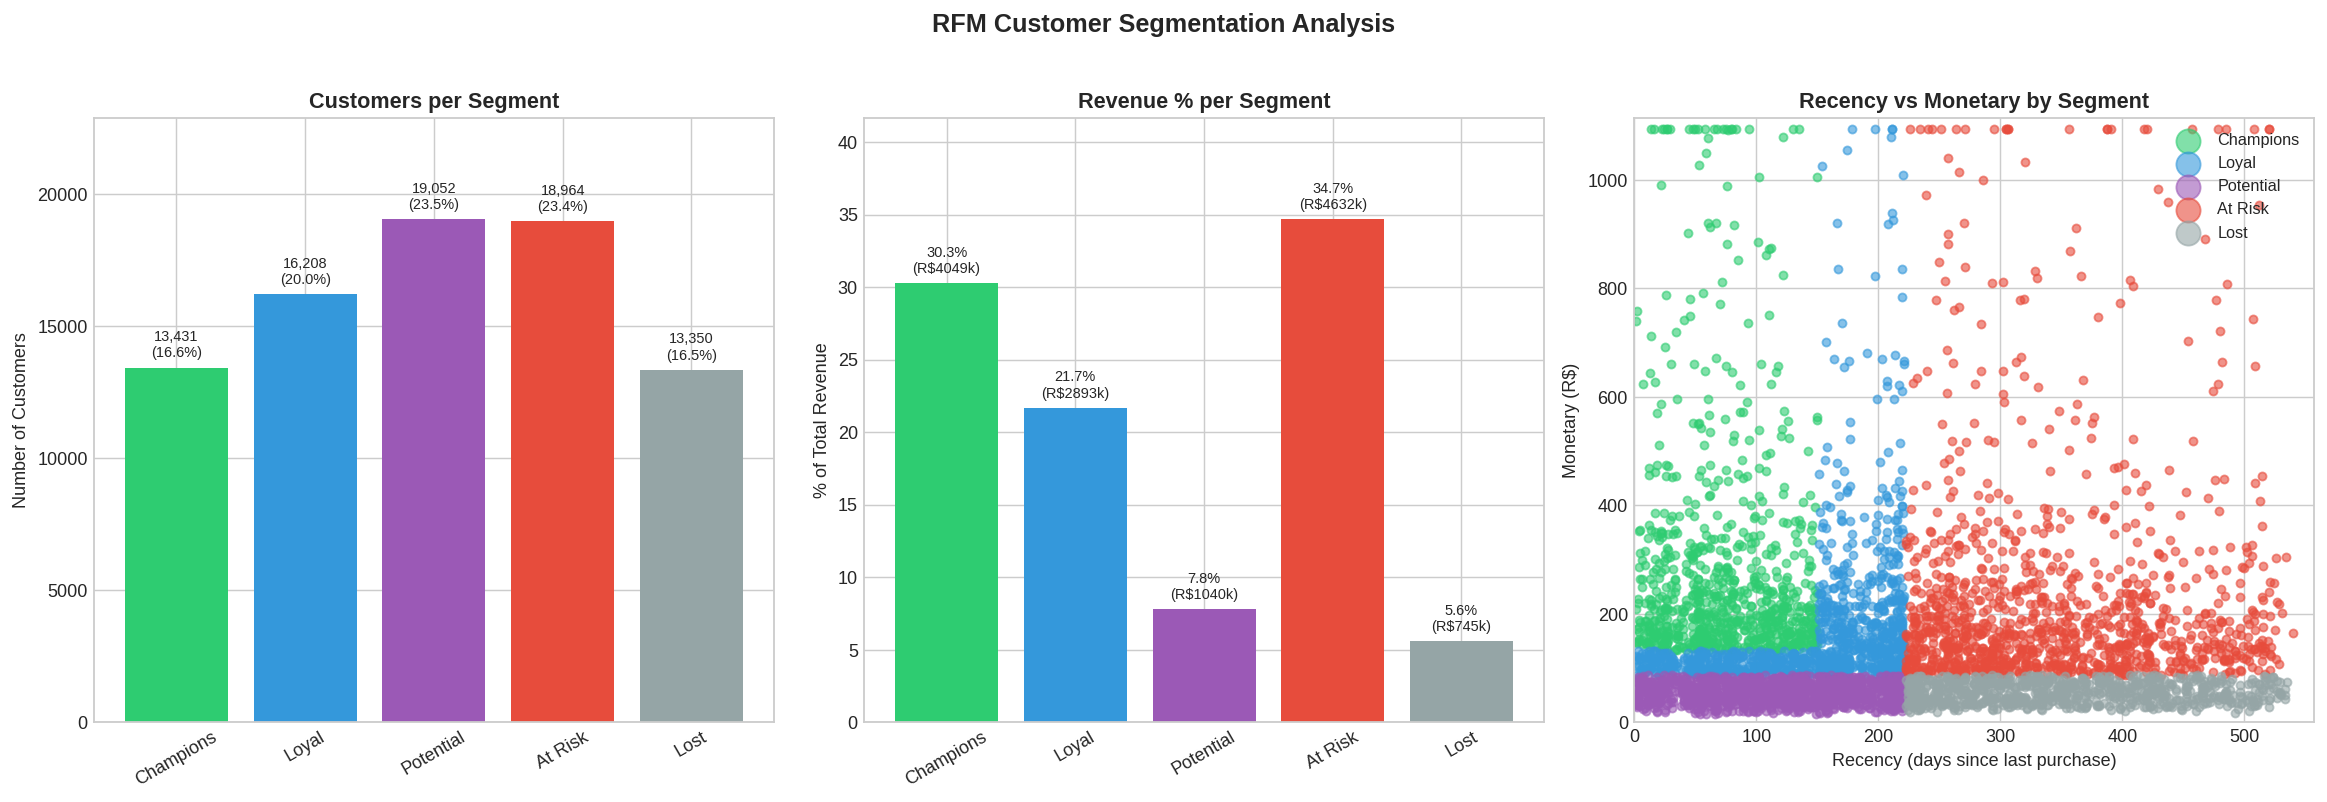

In [ ]:
colors_map = {'Champions':'#2ecc71','Loyal':'#3498db',
               'Potential':'#9b59b6','At Risk':'#e74c3c','Lost':'#95a5a6'}
colors = [colors_map[s] for s in seg_order]

fig, axes = plt.subplots(1, 3, figsize=(18,6))
seg_plot = seg_summary.set_index('segment').reindex(seg_order)

# Chart 1 — Customer count
bars = axes[0].bar(seg_order, seg_plot['customers'], color=colors)
axes[0].bar_label(bars,
    labels=[f"{x:,}\n({y:.1f}%)" for x,y in zip(seg_plot['customers'], seg_plot['customer_pct'])],
    padding=4, fontsize=8)
axes[0].set_title('Customers per Segment', fontweight='bold')
axes[0].set_ylabel('Number of Customers')
axes[0].tick_params(axis='x', rotation=30)
axes[0].set_ylim(0, seg_plot['customers'].max()*1.2)

# Chart 2 — Revenue %
bars2 = axes[1].bar(seg_order, seg_plot['revenue_pct'], color=colors)
axes[1].bar_label(bars2,
    labels=[f"{x:.1f}%\n(R${y/1000:.0f}k)" for x,y in zip(seg_plot['revenue_pct'], seg_plot['total_revenue'])],
    padding=4, fontsize=8)
axes[1].set_title('Revenue % per Segment', fontweight='bold')
axes[1].set_ylabel('% of Total Revenue')
axes[1].tick_params(axis='x', rotation=30)
axes[1].set_ylim(0, seg_plot['revenue_pct'].max()*1.2)

# Chart 3 — Recency vs Monetary scatter
sample = rfm.sample(min(5000, len(rfm)), random_state=42)
for seg in seg_order:
    grp = sample[sample['segment']==seg]
    axes[2].scatter(grp['recency'], grp['monetary_capped'],
                    alpha=0.6, label=seg, s=20, color=colors_map[seg])
axes[2].set_title('Recency vs Monetary by Segment', fontweight='bold')
axes[2].set_xlabel('Recency (days since last purchase)')
axes[2].set_ylabel('Monetary (R$)')
axes[2].legend(fontsize=9, markerscale=3, loc='upper right', framealpha=0.9)
axes[2].set_xlim(0, rfm['recency'].max()+15)
axes[2].set_ylim(0, rfm['monetary_capped'].max()+20)

plt.suptitle('RFM Customer Segmentation Analysis', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 5.9 — Export RFM segments for Power BI and AI chatbot

In [ ]:
rfm.to_csv('/content/clean/rfm_segments.csv', index=False)
print(f"Exported: {rfm.shape[0]:,} customers × {rfm.shape[1]} columns")
print("\nSegment counts:")
print(rfm['segment'].value_counts())

Exported: 81,005 customers × 10 columns

Segment counts:
segment
Potential    19052
At Risk      18964
Loyal        16208
Champions    13431
Lost         13350
Name: count, dtype: int64


---

### 📌 Finding — RFM Customer Segmentation

**Segmentation validation ✓**  
Champions: R=4.51, M=4.49, avg recency 77 days, avg spend R\$301.  
Lost: R=1.49, M=1.51, avg recency 353 days, avg spend R\$56. The model is behaviorally coherent.

**The counterintuitive revenue story**  
**At Risk customers drive 34.7% (R\$4.6M) of revenue — more than Champions (30.3%, R\$4.0M).**  
This reflects their *historical* high-value purchases before they churned.  
They were Olist's best customers. They left. Their past spend still appears in the revenue totals.

**Revenue concentration**  
Champions + At Risk = 40% of customers but **65% of total revenue**.  
At Risk + Lost combined = R\$5.4M (40.3%) — already lost or at severe risk of permanent loss.

**The Potential opportunity**  
Potential is 23.5% of customers but only 7.8% of revenue — the largest  
customer-share vs revenue-share gap. These customers bought recently  
(avg recency 117 days) but spent little (avg R\$55). If they reached  
Loyal avg spend, the incremental opportunity is approximately **R\$2,343,396**.

> **Note on Frequency:** 97% one-time buyer rate makes F a noise variable.  
> This model is effectively RM segmentation — Recency and Monetary carry all signal.

**Business recommendations:**
- **Champions** → protect at all costs; exclusive access, recognition; do NOT discount
- **At Risk** → highest urgency; personalised win-back based on prior category purchases;  
  5% reactivation ≈ R\$230k
- **Potential** → category cross-sell is the lever, not discounting; capitalize on recency  
  window before it closes
- **Lost** → single low-cost mass email; accept most are genuinely gone


---

## Section 6 — Review Analysis <a id='reviews'></a>

**Business questions answered in this section:**
- What is the overall review score distribution?
- Does delivery speed drive customer satisfaction?
- Do different RFM segments leave different scores?

**Connection to previous sections:**  
The delivery-satisfaction relationship links directly to Section 4 (Geography).  
States with slow delivery (BA: 16 days, AM: 25 days) almost certainly show  
lower satisfaction than SP (7 days). This cross-section connection is the  
strongest actionable finding in the entire notebook.

> **Note:** Review analysis uses `master_orders_full` — reviews are not time-sensitive  
> in the same way revenue trends are, and maximum review coverage is preferable.


### 6.1 — Join RFM segments to orders for segment-level analysis

In [ ]:
master_orders_rfm = master_orders_full.merge(
    rfm[['customer_unique_id','segment','R','M','monetary_capped']],
    on='customer_unique_id', how='left')

print(f"master_orders_rfm shape: {master_orders_rfm.shape}")
print(f"Rows with segment:     {master_orders_rfm['segment'].notna().sum():,}")
print(f"Rows without segment:  {master_orders_rfm['segment'].isna().sum():,} "
      f"(soft-launch orders not in stable period)")

### 6.2 — Three charts: score distribution, delivery impact, and segment scores

| Chart | Question |
|-------|----------|
| Score distribution | What does the overall sentiment landscape look like? |
| Delivery days by score | Is delivery the main driver of satisfaction? |
| Score by RFM segment | Do loyal customers rate differently from churned ones? |


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18,6))
score_colors = ['#e74c3c','#e67e22','#f1c40f','#2ecc71','#27ae60']

# Chart 1 — Score distribution
score_counts  = master_orders_full['review_score'].dropna().value_counts().sort_index()
total_reviews = score_counts.sum()
bars = axes[0].bar(score_counts.index, score_counts.values,
                   color=score_colors, edgecolor='white', linewidth=0.5)
axes[0].bar_label(bars,
    labels=[f"{v/total_reviews:.1f}%" for v in score_counts.values],
    padding=4, fontsize=8, fontweight='bold')
axes[0].set_title("Review Score Distribution", fontweight='bold')
axes[0].set_xlabel("Review Score (1–5)")
axes[0].set_ylabel("Number of Reviews")
axes[0].set_ylim(0, score_counts.max()*1.25)

# Chart 2 — Avg delivery days by review score
delivery_by_score = master_orders_full.groupby('review_score')['delivery_days'].mean().round(1)
bars2 = axes[1].bar(delivery_by_score.index, delivery_by_score.values,
                    color=score_colors, edgecolor='white', linewidth=0.5)
axes[1].bar_label(bars2, labels=[f"{v:.1f}d" for v in delivery_by_score.values],
                  padding=4, fontsize=9, fontweight='bold')
axes[1].set_title('Avg Delivery Days by Review Score', fontweight='bold')
axes[1].set_xlabel('Review Score (1–5)')
axes[1].set_ylabel('Average Delivery Days')
axes[1].set_ylim(0, delivery_by_score.max()*1.2)

# Chart 3 — Avg review score by RFM segment
seg_order  = ['Champions','Loyal','Potential','At Risk','Lost']
colors_map = {'Champions':'#2ecc71','Loyal':'#3498db','Potential':'#9b59b6',
               'At Risk':'#e74c3c','Lost':'#95a5a6'}
seg_scores = (master_orders_rfm.groupby('segment')['review_score']
              .mean().reindex(seg_order).round(2))
bars3 = axes[2].bar(seg_scores.index, seg_scores.values,
                    color=[colors_map[s] for s in seg_order],
                    edgecolor='white', linewidth=0.5)
axes[2].bar_label(bars3, labels=[f"{v:.2f}★" for v in seg_scores.values],
                  padding=4, fontsize=9, fontweight='bold')
axes[2].set_title('Avg Review Score by RFM Segment', fontweight='bold')
axes[2].set_xlabel('Customer Segment')
axes[2].set_ylabel('Average Review Score (1–5)')
axes[2].set_ylim(3, 5)
axes[2].tick_params(axis='x', rotation=30)

plt.suptitle('Customer Review Analysis', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Supporting statistics

In [ ]:
print("Score distribution:")
print(score_counts)
print(f"\nOverall avg score: {master_orders_full['review_score'].mean():.2f}")
print(f"% 5-star:          {score_counts[5]/total_reviews*100:.1f}%")
print(f"% 1-star:          {score_counts[1]/total_reviews*100:.1f}%")

print("\nDelivery days by review score:")
print(delivery_by_score)

corr = master_orders_full[['delivery_days','review_score']].corr()
print(f"\nPearson r (delivery_days vs review_score): "
      f"{corr.loc['delivery_days','review_score']:.3f}")

print("\nAvg review score by RFM segment:")
print(seg_scores)

---

### 📌 Finding — Customer Review Analysis

**Overall satisfaction is strong but polarised**  
Overall average score: **4.16★** with **59.3% five-star reviews**.  
The distribution is J-shaped — 1-star reviews (9.7%, 9,167) form the second-largest  
group, with 2-star and 3-star far less common. Delighted and frustrated customers  
both review actively; the underwhelmed middle stays silent.

**Delivery is the single strongest satisfaction driver**  
The delivery-score relationship is perfectly monotonic:

| Score | Avg delivery |
|-------|-------------|
| 1★ | 20.9 days |
| 2★ | 16.2 days |
| 3★ | 13.8 days |
| 4★ | 11.8 days |
| 5★ | 10.2 days |

1-star customers waited **more than twice as long** as 5-star customers (10.7-day gap).  
Pearson r = **-0.335** — every additional delivery day reduces expected score.

**The counterintuitive segment pattern**  
Champions leave the *lowest* scores (4.02★); Lost customers leave the highest (4.27★).  
This reflects **elevated expectations from experienced buyers** — not service quality decline.  
A falling average review score could paradoxically signal improving customer quality.

**Business recommendations:**
- Reducing avg delivery time by 2 days would improve avg scores ~0.06★ and  
  meaningfully reduce the 9.7% one-star rate — publicly visible and deters new buyers
- Set a **12-day delivery SLA** as an internal target — this is the threshold  
  between 4★ and 3★ territory; flag at-risk orders for priority handling
- Monitor Champions' score *trend over time*, not absolute level — a declining  
  Champions trend is the genuine early warning signal to act on


---

# 📊 Key Findings Summary — Olist E-Commerce Analysis <a id='summary'></a>

## Dataset
- **Source:** Olist Brazilian E-Commerce Public Dataset (Kaggle)
- **Scope:** 96,461 delivered orders · 81,005 unique customers · 18-month stable period (Jan 2017 – Jul 2018)
- **Tools:** Python · Pandas · Matplotlib · Seaborn · Plotly

---

## 1. Revenue
- Revenue peaked at **R\$1.15M in November 2017** — a 53.5% MoM spike driven by Black Friday
- 3-month rolling average confirms underlying upward trend throughout the period
- **December 2017 saw a 27% post-holiday correction** — predictable seasonal pattern

## 2. Time Patterns
- Orders concentrated in a broad **10-hour active window (11am–9pm)** — no single lunch spike
- **16:00 is the peak hour** (6,475 orders) but 10 other hours are within 10%
- Midnight hour shows 2,321 orders — likely UTC timezone artifact, not real behaviour

## 3. Products
- **health_beauty** leads revenue (R\$1.1M) with highest penetration (8.73%)
- **watches_gifts** is the premium outlier — #2 revenue, 5.68% penetration, R\$214 AOV (94% above bed_bath_table)
- Items per order: 1.04–1.24 across all categories — no in-category bundling, untapped cross-sell opportunity

## 4. Customers
- **97% of customers (78,591) placed only one order** — typical marketplace model
- Repeat customers generate R\$307 average LTV — 1.9× the one-time buyer average
- New customer acquisition grew **718% from Jan 2017 to Jun 2018**, decelerating to ~6,000–6,500/month

## 5. Cohort Retention
- Month-1 retention: **0.18%–0.72%** — sub-1% consistent with 97% one-time buyer rate
- Retention improved through 2017 (0.28% → 0.72%) — platform maturity drives stickiness
- **Black Friday cohort underperformed** (0.57% vs Oct's 0.72%) — promotional acquisition ≠ loyalty

## 6. Geography
- **SP alone drives 37.4% of revenue** — 3× the next state (RJ). Just 7 of 27 states reach 80%
- **Northern states show highest AOV** (PB: R\$267, AC: R\$250) despite lowest order volumes
- Delivery gap: SP 7 days vs AM/RR 25 days — **3.6× longer** for 18-day difference

## 7. RFM Segmentation
- **At Risk drives 34.7% of revenue (R\$4.6M) — more than Champions (30.3%, R\$4.0M)**
- Champions + At Risk = 40% of customers but 65% of revenue
- **Potential (23.5% of customers) generates only 7.8% of revenue** — largest growth opportunity

## 8. Reviews
- Overall avg: **4.16★** · 59.3% five-star · 9.7% one-star — J-shaped distribution
- Delivery is the #1 satisfaction driver (Pearson r = -0.335): 1★ = 20.9 days vs 5★ = 10.2 days
- **Champions rate lowest (4.02★), Lost rate highest (4.27★)** — reflects elevated expectations, not service decline

---

## Strategic Priority Matrix

| Priority | Segment / Area | Action | Est. Revenue Impact |
|----------|----------------|--------|---------------------|
| 🔴 Urgent | At Risk customers | Win-back campaign | R\$230k+ |
| 🔴 Urgent | Delivery speed | Reduce avg by 2 days | Score +0.06★, fewer 1★ reviews |
| 🟡 High | Potential customers | Category cross-sell | R\$2.3M incremental |
| 🟡 High | Northern states logistics | Partnership review | High AOV market unlocked |
| 🟢 Medium | Champions | Loyalty programme | Protect R\$4M revenue |
| 🟢 Medium | Black Friday spend | Cap promotional budget | Better cohort quality |

---

*Analysis by Dev Gupta · Dataset: Olist Brazilian E-Commerce (Kaggle) · Tools: Python, Pandas, Matplotlib, Seaborn*
